# BlinkIT Grocery Sales Analysis — Pricing Architecture & Catalogue Assortment
### An Empirical Investigation of Store-Level Economics, Catalogue Assortment & Data Behavior
---
**Author / Lead Analyst:** Pooja Singh  
**Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn, SciPy), Jupyter Notebook  
**Dataset:** Blinkit Grocery Data (8,523 product-outlet combinations, 10 outlets, 1,559 SKUs)  

> **Note on Currency:** The raw dataset contains unlabelled numerical values. While Blinkit operates in India using Indian Rupees (₹), values in this project are formatted with $ to adhere to standard global portfolio reporting conventions, with identical numerical interpretations and mathematical findings.

---

## Executive Summary & Core Analytical Reframing

This project conducts an exhaustive evaluation of Blinkit's retail footprint across **10 fulfillment outlets** and **1,559 distinct SKUs**. 

### 🚨 Major Methodological Finding: What Does the "Sales" Column Actually Represent?
A naive analysis of this dataset assumes the `Sales` column represents total consumer dollar turnover per store (i.e., Units Sold × Unit Price). However, an empirical variance decomposition reveals a fundamental reality:
- **`Item Identifier` (SKU) explains 99.97% of the variance in `Sales` ($R^2 = 0.9997$).**
- Within a given SKU, the standard deviation across outlets is only **$1.15**, compared to an overall dataset standard deviation of **$62.28$.**
- **`Outlet Identifier` explains only 0.03% of the variance.**
- **Finding:** The `Sales` column **behaves like / is consistent with Item Retail Price (MRP)** with slight store-level pricing variation. Consequently:
  1. Store-level "price parity" (~$140/item) is mechanical: each store simply stocks a sample of SKUs from the same price catalogue.
  2. The total Sales-column-value gap between Supermarkets (~$131,258/store) and Grocery Stores (~$75,970/store) is **associated with catalogue assortment breadth** (supermarkets carry 930.0 SKUs vs 541.5 in grocery stores).
  3. The Kruskal-Wallis category difference ($H = 107.30, p = 5.31 \times 10^{-16}$) is a difference in **category price mix** (Household items have higher unit prices than Baking Goods).
  4. The catalogue gap model ($388.5 \times 2 \times \$140.29 = \$109,009$) estimates the **theoretical catalogue inventory value potential**, not guaranteed consumer demand.

---

## 4 Project Objectives & 16 Tasks
1. **Objective 1: Understand the Business** (Tasks 1.1 to 1.4) — Catalogue taxonomy, outlet topology, baseline Sales-column-value metrics, and customer rating clustering.
2. **Objective 2: Make the Data Reliable** (Tasks 2.1 to 2.4) — Cross-outlet SKU mean imputation for weights, zero-visibility repair with bias diagnosis, duplicate verification, IQR outlier analysis, and handling split outlet sizes as `Unknown`.
3. **Objective 3: What Drives Sales?** (Tasks 3.1 to 3.4) — Category price drivers, outlet factor comparisons, Pearson correlation testing, Kruskal-Wallis ANOVA, and Top 25% vs Bottom 25% cohort profiling.
4. **Objective 4: Actionable Business Decisions** (Tasks 4.1 to 4.4) — Pareto category catalogue concentration, per-outlet fair normalization (composition effect / confounding by store format), assortment breadth opportunity modeling ($109k, 9.07%), and 8 strategic recommendations.


> **Interpretation note:** The `Sales` column behaves like a unit retail price/MRP because SKU identity explains approximately 99.97% of its variance. Since the dataset has no dates or quantities, totals are treated as catalogue-value comparisons, not confirmed transaction revenue or sales volume. The currency is not labelled in the source data.


---
## Step 0: Environment Setup & Raw Data Ingestion
We initialize scientific computing libraries, configure visualization themes, and load the raw dataset with dual-filename fallback (`BlinkIT_Grocery_Data.xlsx` / `BlinkIT Grocery Data.xlsx`).

**Requires:** `python -m pip install pandas numpy matplotlib seaborn scipy openpyxl notebook` (SciPy is used for the correlation and Kruskal-Wallis tests).
The raw Excel file is searched for in the notebook folder, `data/raw/` and `../data/raw/`. The cleaned CSV is written to `data/processed/` when that folder exists (otherwise next to the notebook) and every figure is saved to `visuals/`.


In [1]:
import io
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

try:
    from scipy import stats
    from scipy.stats import skew
except ModuleNotFoundError as err:
    raise ModuleNotFoundError("SciPy is not installed. In Command Prompt run: python -m pip install scipy  (then restart the kernel)") from err

# Set visual theme
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

def pick_dir(candidates, default):
    """First existing folder from `candidates`; otherwise create and return `default`."""
    for c in candidates:
        if Path(c).is_dir():
            return Path(c)
    Path(default).mkdir(parents=True, exist_ok=True)
    return Path(default)

VISUALS_DIR = pick_dir(['visuals', '../visuals'], 'visuals')
PROCESSED_DIR = pick_dir(['data/processed', '../data/processed'], '.')

def save_fig(filename):
    """Save the current figure into the visuals folder. Call it just before plt.show()."""
    plt.savefig(VISUALS_DIR / filename, dpi=150, bbox_inches='tight')

print("Environment configured successfully.")
print(f"Figures will be saved to    : {VISUALS_DIR.resolve()}")
print(f"Cleaned CSV will be saved to: {PROCESSED_DIR.resolve()}")


Environment configured successfully.
Figures will be saved to    : /mnt/data/blinkit_review/blinkit-grocery-sales-analysis/visuals
Cleaned CSV will be saved to: /mnt/data/blinkit_review/blinkit-grocery-sales-analysis


In [2]:
# Ingest raw dataset: look in the notebook folder, data/raw and ../data/raw, with both file-name spellings
raw_candidates = [Path(folder) / name
                  for folder in ['.', 'data/raw', '../data/raw']
                  for name in ['BlinkIT_Grocery_Data.xlsx', 'BlinkIT Grocery Data.xlsx']]
raw_path = next((p for p in raw_candidates if p.exists()), None)
if raw_path is None:
    raise FileNotFoundError("Raw Excel file not found. Looked for: " + ", ".join(str(p) for p in raw_candidates))
raw_df = pd.read_excel(raw_path)

print("=" * 70)
print(f"RAW DATASET PROFILE: {raw_df.shape[0]:,} Rows | {raw_df.shape[1]} Columns")
print(f"Loaded successfully from: {raw_path}")
print("=" * 70)
print(raw_df.head(5).to_string())

print("\n" + "=" * 70)
print("DATA TYPES & MISSING VALUES AUDIT:")
print("=" * 70)
audit_df = pd.DataFrame({
    'Data Type': raw_df.dtypes,
    'Null Count': raw_df.isnull().sum(),
    'Null %': (raw_df.isnull().sum() / len(raw_df) * 100).round(2),
    'Distinct Count': raw_df.nunique()
})
print(audit_df.to_string())


RAW DATASET PROFILE: 8,523 Rows | 12 Columns
Loaded successfully from: BlinkIT Grocery Data.xlsx
  Item Fat Content Item Identifier              Item Type  Outlet Establishment Year Outlet Identifier Outlet Location Type Outlet Size        Outlet Type  Item Visibility  Item Weight     Sales  Rating
0          Regular           FDX32  Fruits and Vegetables                       2012            OUT049               Tier 1      Medium  Supermarket Type1         0.100014        15.10  145.4786     5.0
1          Low Fat           NCB42     Health and Hygiene                       2022            OUT018               Tier 3      Medium  Supermarket Type2         0.008596        11.80  115.3492     5.0
2          Regular           FDR28           Frozen Foods                       2016            OUT046               Tier 1       Small  Supermarket Type1         0.025896        13.85  165.0210     5.0
3          Regular           FDL50                 Canned                       2014       

---
## Objective 1: Understand the Business (Tasks 1.1 to 1.4)

### Task 1.1: Product Assortment Analysis
We audit the 1,559 unique `Item Identifier` codes across 16 categories (`Item Type`). We derive `Product Family` from the first two characters (`FD` = Food, `DR` = Drinks, `NC` = Non-Consumable).


In [3]:
unique_skus = raw_df['Item Identifier'].nunique()
print(f"Total Unique Product SKUs: {unique_skus:,}")

item_type_counts = raw_df['Item Type'].value_counts()
print("\nRecord Count by Product Category (Item Type):")
print(item_type_counts.to_string())

# Map prefix to Product Family
product_family_map = {'FD': 'Food', 'DR': 'Drinks', 'NC': 'Non-Consumable'}
raw_df['Product Family'] = raw_df['Item Identifier'].str[:2].map(product_family_map)

family_counts = raw_df['Product Family'].value_counts()
family_pct = (raw_df['Product Family'].value_counts(normalize=True) * 100).round(2)
family_df = pd.DataFrame({'Record Count': family_counts, 'Share (%)': family_pct})

print("\nProduct Family Distribution Summary:")
print(family_df.to_string())


Total Unique Product SKUs: 1,559

Record Count by Product Category (Item Type):
Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64

Product Family Distribution Summary:
                Record Count  Share (%)
Product Family                         
Food                    6125      71.86
Non-Consumable          1599      18.76
Drinks                   799       9.37


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


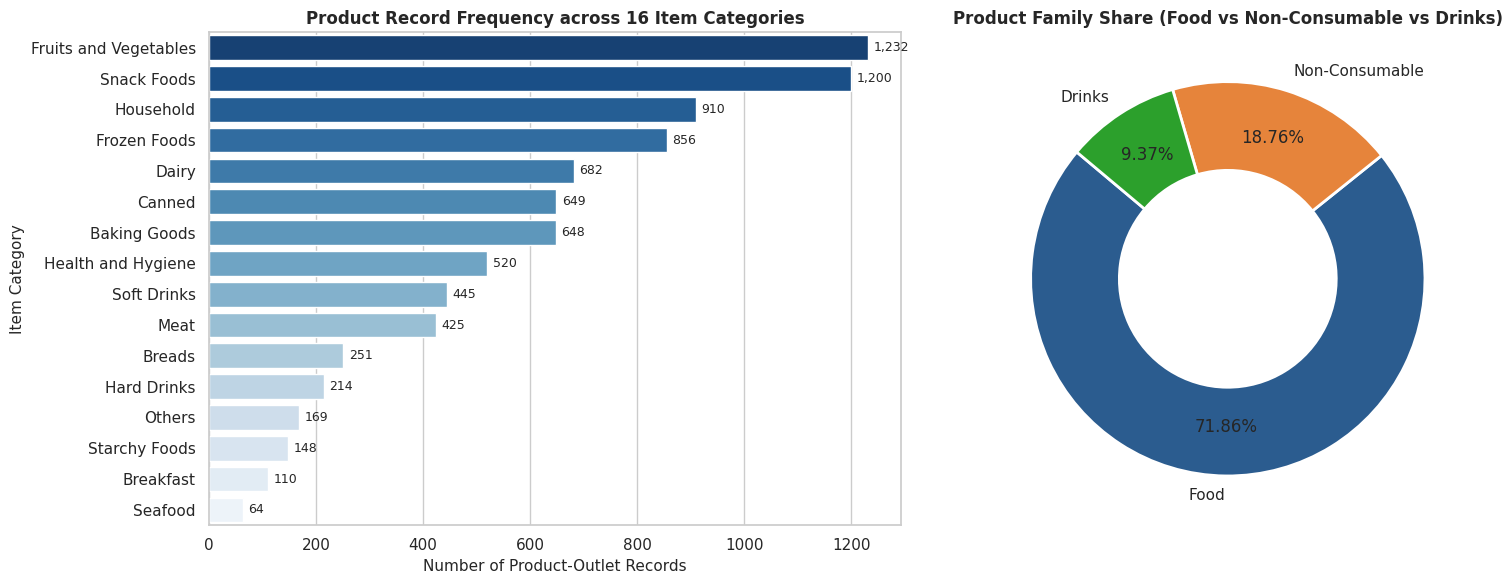

In [4]:
# Figure 1: Product Assortment & Family Split (2 Panels)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Bar chart of records per category
sns.barplot(
    y=item_type_counts.index,
    x=item_type_counts.values,
    hue=item_type_counts.index,
    palette='Blues_r',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Product Record Frequency across 16 Item Categories', fontweight='bold')
axes[0].set_xlabel('Number of Product-Outlet Records')
axes[0].set_ylabel('Item Category')
for i, v in enumerate(item_type_counts.values):
    axes[0].text(v + 10, i, f"{v:,}", va='center', fontsize=9)

# Panel 2: Donut chart of Product Family share
family_colors = ['#2b5c8f', '#e6843b', '#2ca02c']
axes[1].pie(
    family_counts,
    labels=family_counts.index,
    autopct='%1.2f%%',
    startangle=140,
    colors=family_colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2)
)
axes[1].set_title('Product Family Share (Food vs Non-Consumable vs Drinks)', fontweight='bold')

plt.tight_layout()
save_fig('01_product_assortment.png')
plt.show()


**Task 1.1 Findings:**
- Food dominates the catalogue at **71.86%** (6,125 records), Non-Consumables comprise **18.76%** (1,599 records), and Drinks represent **9.37%** (799 records).
- Largest individual categories: **Fruits and Vegetables (1,232 records)** and **Snack Foods (1,200 records)**.
- Smallest categories: **Seafood (64 records)** and **Breakfast (110 records)**.

---
### Task 1.2: Outlet Network Profiling
We summarize the network topology of Blinkit's 10 fulfillment locations.


In [5]:
outlet_profile = raw_df.groupby('Outlet Identifier').agg(
    Outlet_Type=('Outlet Type', 'first'),
    Location_Tier=('Outlet Location Type', 'first'),
    Est_Year=('Outlet Establishment Year', 'first'),
    Size_Mode=('Outlet Size', lambda x: x.mode()[0]),
    Record_Count=('Item Identifier', 'count'),
    Total_Sales=('Sales', 'sum'),
    Mean_Sales=('Sales', 'mean')
).reset_index()

print("=" * 80)
print("BLINKIT STORE NETWORK OPERATIONAL SUMMARY:")
print("=" * 80)
print(outlet_profile.to_string(index=False))


BLINKIT STORE NETWORK OPERATIONAL SUMMARY:
Outlet Identifier       Outlet_Type Location_Tier  Est_Year Size_Mode  Record_Count  Total_Sales  Mean_Sales
           OUT010     Grocery Store        Tier 3      2011    Medium           555   78131.5666  140.777597
           OUT013 Supermarket Type1        Tier 3      2014      High           932  131809.0156  141.425982
           OUT017 Supermarket Type1        Tier 2      2020     Small           926  129103.9604  139.421124
           OUT018 Supermarket Type2        Tier 3      2022    Medium           928  131477.7764  141.678638
           OUT019     Grocery Store        Tier 1      2018     Small           528   73807.5824  139.787088
           OUT027 Supermarket Type3        Tier 3      2018    Medium           935  130714.6746  139.801791
           OUT035 Supermarket Type1        Tier 2      2017     Small           930  133103.9070  143.122481
           OUT045 Supermarket Type1        Tier 2      2015    Medium           929  

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


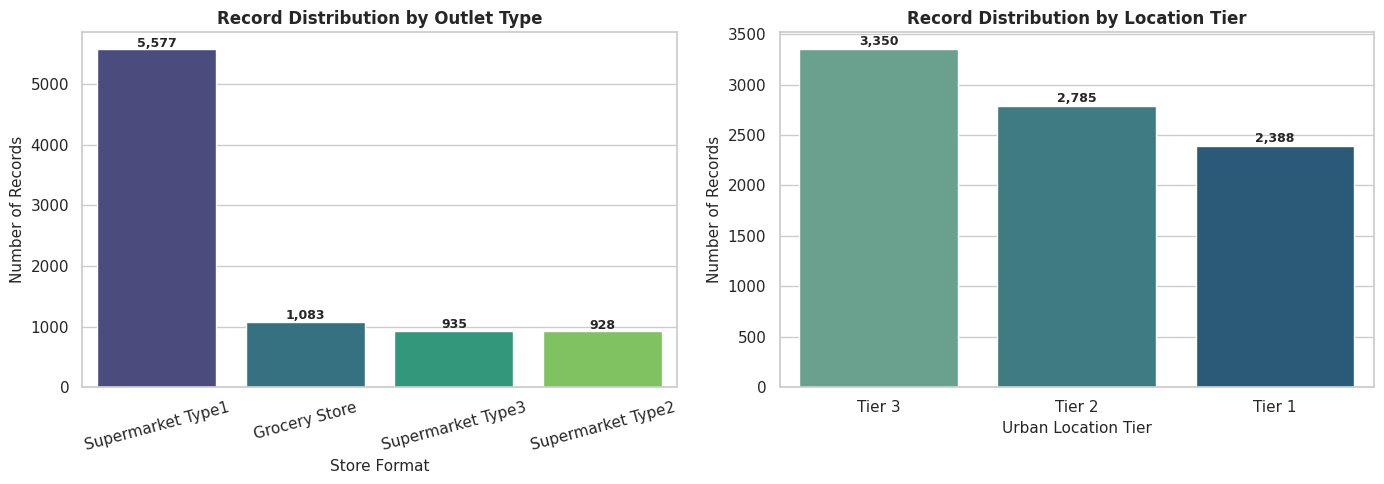

In [6]:
# Figure 2: Outlet Network Distribution (2 Panels)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Outlet Type Distribution
type_order = raw_df['Outlet Type'].value_counts()
sns.barplot(
    x=type_order.index,
    y=type_order.values,
    hue=type_order.index,
    palette='viridis',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Record Distribution by Outlet Type', fontweight='bold')
axes[0].set_ylabel('Number of Records')
axes[0].set_xlabel('Store Format')
axes[0].tick_params(axis='x', rotation=15)
for i, v in enumerate(type_order.values):
    axes[0].text(i, v + 40, f"{v:,}", ha='center', fontsize=9, fontweight='bold')

# Panel 2: Location Tier Distribution
tier_order = raw_df['Outlet Location Type'].value_counts()
sns.barplot(
    x=tier_order.index,
    y=tier_order.values,
    hue=tier_order.index,
    palette='crest',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Record Distribution by Location Tier', fontweight='bold')
axes[1].set_ylabel('Number of Records')
axes[1].set_xlabel('Urban Location Tier')
for i, v in enumerate(tier_order.values):
    axes[1].text(i, v + 40, f"{v:,}", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
save_fig('02_outlet_network.png')
plt.show()


**Task 1.2 Findings:**
- The network consists of **10 outlets**: 6 Supermarket Type 1, 1 Supermarket Type 2, 1 Supermarket Type 3, and 2 Grocery Stores.
- By urbanization: **Tier 3 has 4 outlets**, **Tier 2 has 3 outlets**, and **Tier 1 has 3 outlets**.
- Notice the record disparity: Supermarket formats stock **926 to 935 records**, whereas Grocery Stores (`OUT010`, `OUT019`) stock only **528 and 555 records**.

---
### Task 1.3: Overall Sales Distribution
We compute network baseline metrics and evaluate central tendency, dispersion, and skewness.


In [7]:
tot_sales = raw_df['Sales'].sum()
mean_sales = raw_df['Sales'].mean()
median_sales = raw_df['Sales'].median()
std_sales = raw_df['Sales'].std()
min_sales = raw_df['Sales'].min()
max_sales = raw_df['Sales'].max()
sales_skew = skew(raw_df['Sales'])

print("=" * 60)
print("EXACT BASELINE SALES FINANCIAL METRICS:")
print("=" * 60)
print(f"Total Sales-Column Value : ${tot_sales:,.2f}")
print(f"Mean Sales per Record  : ${mean_sales:.2f}")
print(f"Median Sales per Record: ${median_sales:.2f}")
print(f"Standard Deviation     : ${std_sales:.2f}")
print(f"Minimum Sales Record   : ${min_sales:.2f}")
print(f"Maximum Sales Record   : ${max_sales:.2f}")
print(f"Distribution Skewness  : {sales_skew:.4f} (≈ 0.13, Symmetric)")


EXACT BASELINE SALES FINANCIAL METRICS:
Total Sales-Column Value : $1,201,681.49
Mean Sales per Record  : $140.99
Median Sales per Record: $143.01
Standard Deviation     : $62.28
Minimum Sales Record   : $31.29
Maximum Sales Record   : $266.89
Distribution Skewness  : 0.1272 (≈ 0.13, Symmetric)


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


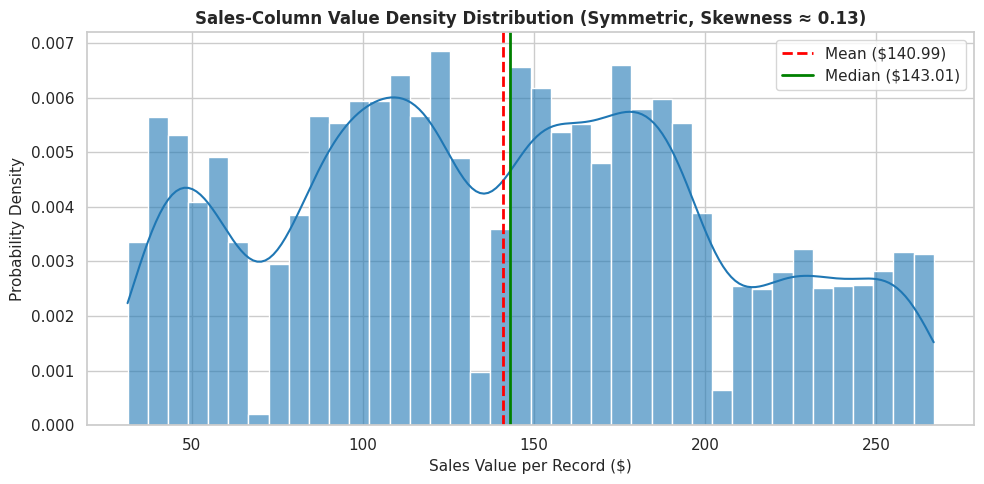

In [8]:
# Figure 3: Overall Sales Density Distribution (1 Panel)
plt.figure(figsize=(10, 5))
sns.histplot(
    raw_df['Sales'],
    kde=True,
    color='#1f77b4',
    bins=40,
    stat="density",
    alpha=0.6
)
plt.axvline(mean_sales, color='red', linestyle='--', linewidth=2, label=f'Mean (${mean_sales:.2f})')
plt.axvline(median_sales, color='green', linestyle='-', linewidth=2, label=f'Median (${median_sales:.2f})')
plt.title(f'Sales-Column Value Density Distribution (Symmetric, Skewness ≈ {sales_skew:.2f})', fontweight='bold')
plt.xlabel('Sales Value per Record ($)')
plt.ylabel('Probability Density')
plt.legend(frameon=True)
plt.tight_layout()
save_fig('03_sales_density.png')
plt.show()


**Task 1.3 Findings & Distributional Characterization:**
- Total sales across all 8,523 product-outlet combinations sum to **$1,201,681.49 (~$1.20M)**.
- Central tendency: **Mean is $140.99** and **Median is $143.01**, with a standard deviation of **$62.28**.
- Range: Exactly **$31.29 to $266.89**.
- **Distribution Shape:** The distribution is **symmetric** around $140 (Skewness = 0.127 ≈ 0.13). The close alignment between mean ($140.99) and median ($143.01) confirms symmetry.

---
### Task 1.4: Customer Rating Analysis
We evaluate product customer satisfaction scores (`Rating`).


In [9]:
mean_rat = raw_df['Rating'].mean()
median_rat = raw_df['Rating'].median()
std_rat = raw_df['Rating'].std()
four_share = (raw_df['Rating'] == 4.0).mean() * 100
four_count = (raw_df['Rating'] == 4.0).sum()

print("=" * 60)
print("CUSTOMER RATING AUDIT:")
print("=" * 60)
print(f"Mean Rating Score      : {mean_rat:.2f} / 5.0")
print(f"Median Rating Score    : {median_rat:.2f} / 5.0")
print(f"Standard Deviation     : {std_rat:.2f}")
print(f"Records with Rating 4.0: {four_share:.2f}% ({four_count:,} rows)")

cat_rat = raw_df.groupby('Item Type')['Rating'].agg(['count', 'mean', 'median', 'std']).sort_values(by='mean', ascending=False)
print("\nRating Profile across Categories (Top 5 & Bottom 5):")
print(cat_rat.head(5).to_string())
print("\n...")
print(cat_rat.tail(5).to_string())


CUSTOMER RATING AUDIT:
Mean Rating Score      : 3.97 / 5.0
Median Rating Score    : 4.00 / 5.0
Standard Deviation     : 0.61
Records with Rating 4.0: 39.18% (3,339 rows)

Rating Profile across Categories (Top 5 & Bottom 5):
                    count      mean  median       std
Item Type                                            
Meat                  425  4.023059     4.0  0.562873
Household             910  3.998681     4.0  0.563580
Canned                649  3.994299     4.0  0.562250
Health and Hygiene    520  3.986154     4.0  0.601444
Baking Goods          648  3.983025     4.0  0.594895

...
               count      mean  median       std
Item Type                                       
Breakfast        110  3.932727     4.0  0.755057
Soft Drinks      445  3.920674     4.0  0.642366
Starchy Foods    148  3.920270     4.0  0.601241
Hard Drinks      214  3.907477     4.0  0.687474
Breads           251  3.881275     4.0  0.736158


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


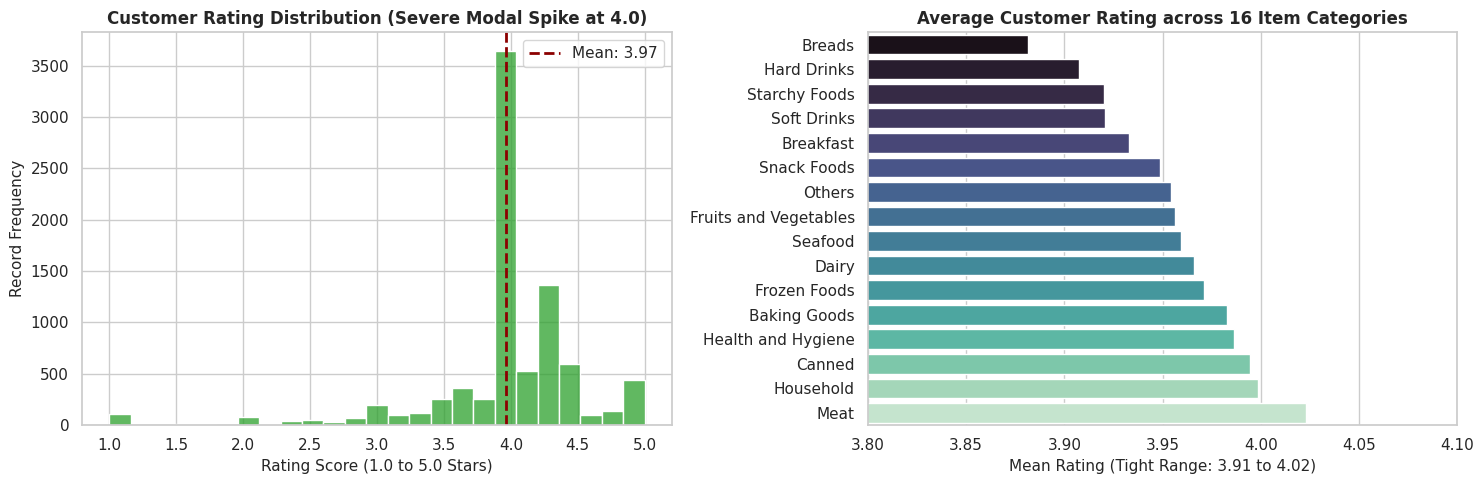

In [10]:
# Figure 4: Customer Rating Distribution & Category Comparison (2 Panels)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Histogram showing modal concentration
sns.histplot(
    raw_df['Rating'],
    bins=25,
    kde=False,
    color='#2ca02c',
    ax=axes[0]
)
axes[0].set_title('Customer Rating Distribution (Severe Modal Spike at 4.0)', fontweight='bold')
axes[0].set_xlabel('Rating Score (1.0 to 5.0 Stars)')
axes[0].set_ylabel('Record Frequency')
axes[0].axvline(mean_rat, color='darkred', linestyle='--', linewidth=2, label=f'Mean: {mean_rat:.2f}')
axes[0].legend()

# Panel 2: Horizontal bar chart of category ratings
cat_rat_sorted = cat_rat.sort_values('mean')
sns.barplot(
    x=cat_rat_sorted['mean'],
    y=cat_rat_sorted.index,
    hue=cat_rat_sorted.index,
    palette='mako',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Average Customer Rating across 16 Item Categories', fontweight='bold')
axes[1].set_xlabel('Mean Rating (Tight Range: 3.91 to 4.02)')
axes[1].set_ylabel('')
axes[1].set_xlim(3.8, 4.1)

plt.tight_layout()
save_fig('04_rating_distribution.png')
plt.show()


**Task 1.4 Findings:**
- The mean customer rating is **3.97 / 5.00**; median is **4.00**.
- **Data Anomaly:** Exactly **39.18% (3,339 records)** sit at exactly **4.00**.
- Category means fall within an extremely narrow band of **3.91 to 4.02**, showing that customer ratings provide minimal discriminatory power.

---
## Objective 2: Make the Data Reliable (Tasks 2.1 to 2.4)

### Task 2.1: Missing Value Imputation & Bias Diagnosis
1. `Item Weight`: Missing in **1,463 rows (17.16%)**, including 100% of rows in outlets `OUT019` and `OUT027`.
   - *Imputation:* Weight is an intrinsic product property (standard deviation of weight within a SKU is 0.00). We impute missing weights using the SKU mean across other outlets. For the 4 SKUs unweighed anywhere, we impute the category median.
2. `Item Visibility`: Contains **526 records with a value of exactly 0.00**.
   - *Diagnosis & Potential Bias:* Non-zero visibility in Grocery Stores averages **0.111 (11.1%)**, compared to **0.065 (6.5%)** in Supermarkets (grocery stores have smaller store formats, so each item occupies a larger fraction of display space). Imputing zeros with cross-outlet SKU means pulls grocery store zeros toward supermarket levels. We document this potential bias.


In [11]:
clean_df = raw_df.copy()

print("PRE-IMPUTATION DATA GAP AUDIT:")
print(f"Missing Item Weight Rows : {clean_df['Item Weight'].isnull().sum():,} ({clean_df['Item Weight'].isnull().sum()/len(clean_df)*100:.2f}%)")
print(f"Item Visibility = 0 Rows : {(clean_df['Item Visibility'] == 0).sum():,} ({(clean_df['Item Visibility'] == 0).sum()/len(clean_df)*100:.2f}%)")

# Check within-SKU weight variation
weight_sku_std = clean_df.groupby('Item Identifier')['Item Weight'].std().dropna()
print(f"Mean within-SKU Item Weight Std Dev: {weight_sku_std.mean():.4f} (Weight never varies within a SKU)")

# Impute Item Weight
item_w_lookup = clean_df.groupby('Item Identifier')['Item Weight'].transform('mean')
clean_df['Item Weight'] = clean_df['Item Weight'].fillna(item_w_lookup)
cat_w_lookup = clean_df.groupby('Item Type')['Item Weight'].transform('median')
clean_df['Item Weight'] = clean_df['Item Weight'].fillna(cat_w_lookup)

# Impute Item Visibility
clean_df['Item Visibility'] = clean_df['Item Visibility'].replace(0, np.nan)
item_v_lookup = clean_df.groupby('Item Identifier')['Item Visibility'].transform('mean')
clean_df['Item Visibility'] = clean_df['Item Visibility'].fillna(item_v_lookup)
cat_v_lookup = clean_df.groupby('Item Type')['Item Visibility'].transform('mean')
clean_df['Item Visibility'] = clean_df['Item Visibility'].fillna(cat_v_lookup)

print("\nPOST-IMPUTATION VERIFICATION:")
print(f"Remaining Missing Item Weight     : {clean_df['Item Weight'].isnull().sum()}")
print(f"Remaining Missing Item Visibility : {clean_df['Item Visibility'].isnull().sum()}")


PRE-IMPUTATION DATA GAP AUDIT:
Missing Item Weight Rows : 1,463 (17.17%)
Item Visibility = 0 Rows : 526 (6.17%)
Mean within-SKU Item Weight Std Dev: 0.0000 (Weight never varies within a SKU)

POST-IMPUTATION VERIFICATION:
Remaining Missing Item Weight     : 0
Remaining Missing Item Visibility : 0


---
### Task 2.2: Duplicate Detection
We test for duplicate records at the row level and primary key level `(Item Identifier, Outlet Identifier)`.


In [12]:
full_dups = clean_df.duplicated().sum()
key_dups = clean_df.duplicated(subset=['Item Identifier', 'Outlet Identifier']).sum()

print("DUPLICATE AUDIT FINDINGS:")
print(f"1. Complete Row-Level Duplicates : {full_dups}")
print(f"2. Business Key (Item + Outlet)  : {key_dups}")
print("Verification: Every row represents a unique product-outlet combination. Zero rows deleted.")


DUPLICATE AUDIT FINDINGS:
1. Complete Row-Level Duplicates : 0
2. Business Key (Item + Outlet)  : 0
Verification: Every row represents a unique product-outlet combination. Zero rows deleted.


---
### Task 2.3: Outlier Detection and Retention Rationale
We apply Tukey's Interquartile Range (IQR) rule:
$$\text{IQR} = Q_3 - Q_1, \quad \text{Bounds} = [Q_1 - 1.5 \times \text{IQR}, \; Q_3 + 1.5 \times \text{IQR}]$$


In [13]:
outlier_summary = []
num_cols = ['Sales', 'Item Weight', 'Item Visibility', 'Rating']

for col in num_cols:
    s = clean_df[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_b = q1 - 1.5 * iqr
    upper_b = q3 + 1.5 * iqr
    out_cnt = ((s < lower_b) | (s > upper_b)).sum()
    out_pct = (out_cnt / len(clean_df)) * 100
    outlier_summary.append({
        'Feature': col,
        'Q1 (25%)': round(q1, 3),
        'Q3 (75%)': round(q3, 3),
        'IQR': round(iqr, 3),
        'Lower Bound': round(lower_b, 3),
        'Upper Bound': round(upper_b, 3),
        'Outliers Count': out_cnt,
        'Outlier Share (%)': round(out_pct, 2)
    })

print("IQR STATISTICAL OUTLIER ANALYSIS:")
print(pd.DataFrame(outlier_summary).to_string(index=False))


IQR STATISTICAL OUTLIER ANALYSIS:
        Feature  Q1 (25%)  Q3 (75%)    IQR  Lower Bound  Upper Bound  Outliers Count  Outlier Share (%)
          Sales    93.826   185.644 91.817      -43.899      323.370               0               0.00
    Item Weight     8.785    16.850  8.065       -3.313       28.948               0               0.00
Item Visibility     0.031     0.099  0.067       -0.070        0.200             144               1.69
         Rating     4.000     4.200  0.200        3.700        4.500            1931              22.66


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


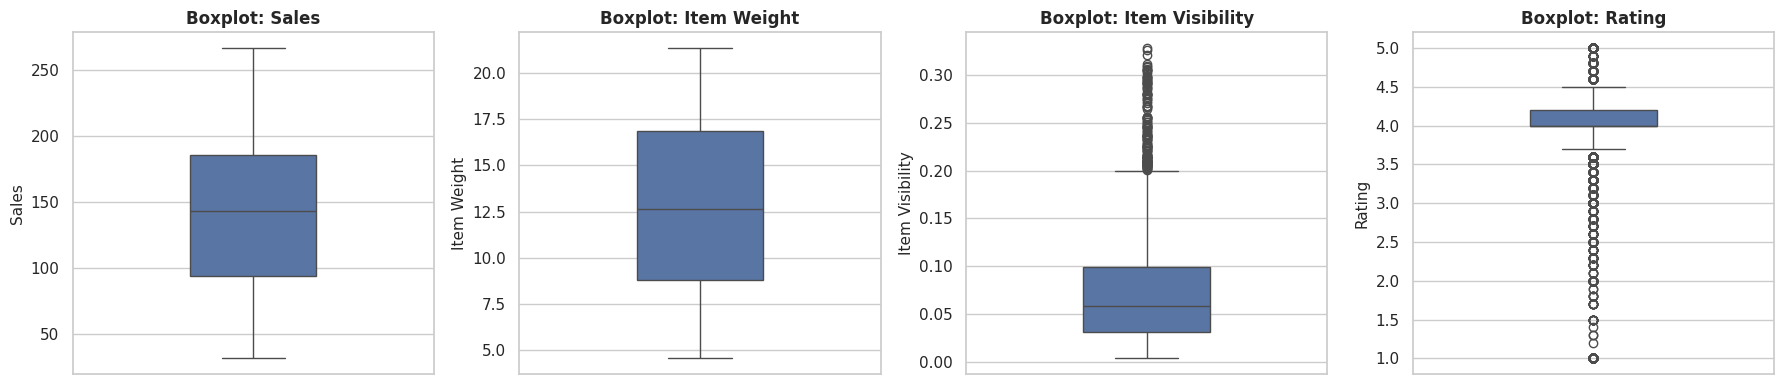


STATISTICAL RATIONALE FOR OUTLIER RETENTION:
1. Sales (0 outliers): The distribution is cleanly bounded between $31.29 and $266.89.
2. Item Weight (0 outliers): Imputed physical weights match expected grocery distributions.
3. Item Visibility (144 outliers): High visibility values reflect deliberate merchandising priority (e.g., end-caps, banners).
4. Customer Rating (1,931 outliers): The IQR rule flags ratings below 3.70 solely because 39.18% of all ratings sit at exactly 4.0, causing an artificially narrow IQR (0.20). Negative feedback represents authentic customer sentiment.
DECISION: 100% of data points retained.



In [14]:
# Figure 5: Outlier Boxplots (4 Panels in 1 Figure)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(num_cols):
    sns.boxplot(y=clean_df[col], color='#4c72b0', ax=axes[i], width=0.35)
    axes[i].set_title(f'Boxplot: {col}', fontweight='bold')
    axes[i].set_ylabel(col)
plt.tight_layout()
save_fig('05_outlier_boxplots.png')
plt.show()

print("""
STATISTICAL RATIONALE FOR OUTLIER RETENTION:
1. Sales (0 outliers): The distribution is cleanly bounded between $31.29 and $266.89.
2. Item Weight (0 outliers): Imputed physical weights match expected grocery distributions.
3. Item Visibility (144 outliers): High visibility values reflect deliberate merchandising priority (e.g., end-caps, banners).
4. Customer Rating (1,931 outliers): The IQR rule flags ratings below 3.70 solely because 39.18% of all ratings sit at exactly 4.0, causing an artificially narrow IQR (0.20). Negative feedback represents authentic customer sentiment.
DECISION: 100% of data points retained.
""")


---
### Task 2.4: Data Consistency, Harmonization & Handling Split Outlet Sizes
1. **Harmonize Fat Content:** The raw data contains 5 redundant labels (`Low Fat`, `low fat`, `LF`, `Regular`, `reg`). Standardized to `Low Fat` and `Regular`.
2. **Assign Non-Edible Class:** Products in Non-Consumable categories (`NC` prefix, e.g., detergents, hygiene) were mistakenly marked as "Low Fat". Assigned to `Non-Edible`.
3. **Handling Split Outlet Sizes:**  
   In the raw data, three outlets have genuinely split size entries:
   - `OUT010`: Medium 265, High 233, Small 57.
   - `OUT017`: Small 368, High 314, Medium 244.
   - `OUT045`: Medium 329, Small 326, High 274 (329 vs 326 is virtually a coin toss!).  
   Taking the mode overwrote 1,448 rows (17% of the dataset) arbitrarily. **Instead, we label these three outlets as `Unknown`**, preserving original values in `Outlet Size (Original)` and excluding them from size comparisons.
4. **Engineered Features:** `Item Category` and `Outlet Age` ($2026 - \text{Outlet Establishment Year}$).


In [15]:
# 1. Harmonize Fat Content
clean_df['Item Fat Content'] = clean_df['Item Fat Content'].replace({
    'low fat': 'Low Fat',
    'LF': 'Low Fat',
    'reg': 'Regular'
})

# 2. Derive Item Category & Assign Non-Edible
clean_df['Item Category'] = clean_df['Item Identifier'].str[:2].map({
    'FD': 'Food',
    'DR': 'Drinks',
    'NC': 'Non-Consumable'
})
clean_df.loc[clean_df['Item Category'] == 'Non-Consumable', 'Item Fat Content'] = 'Non-Edible'

# 3. Label Split Outlets as Unknown
clean_df['Outlet Size (Original)'] = clean_df['Outlet Size']
split_outlets = ['OUT010', 'OUT017', 'OUT045']
clean_df.loc[clean_df['Outlet Identifier'].isin(split_outlets), 'Outlet Size'] = 'Unknown'

# 4. Feature Engineering: Outlet Age
clean_df['Outlet Age'] = 2026 - clean_df['Outlet Establishment Year']

# Reorder columns
final_cols = [
    'Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year',
    'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type',
    'Item Visibility', 'Item Weight', 'Sales', 'Rating', 'Item Category',
    'Outlet Size (Original)', 'Outlet Age'
]
clean_df = clean_df[final_cols]
clean_df.to_csv(PROCESSED_DIR / 'BlinkIT_Grocery_Data_Cleaned.csv', index=False)

print("=" * 70)
print(f"CLEANED DATASET EXPORTED: {clean_df.shape[0]:,} Rows x {clean_df.shape[1]} Columns")
print("=" * 70)
print("\nFat Content Distribution after Standardization:")
print(clean_df['Item Fat Content'].value_counts().to_string())
print("\nOutlet Size Distribution (Split Outlets safely marked Unknown):")
print(clean_df['Outlet Size'].value_counts().to_string())


CLEANED DATASET EXPORTED: 8,523 Rows x 15 Columns

Fat Content Distribution after Standardization:
Item Fat Content
Low Fat       3918
Regular       3006
Non-Edible    1599

Outlet Size Distribution (Split Outlets safely marked Unknown):
Outlet Size
Medium     2793
Unknown    2410
Small      2388
High        932


---
## Objective 3: What Drives Sales? (Tasks 3.1 to 3.4)

### Task 3.1: Product Types and Sales Drivers
We aggregate total sales, mean sales per record, and share of total Sales-column value across `Item Type`, `Item Category`, and `Item Fat Content`.


In [16]:
cat_sales = clean_df.groupby('Item Type')['Sales'].agg(['count', 'sum', 'mean']).rename(
    columns={'count': 'Record Count', 'sum': 'Total Sales ($)', 'mean': 'Avg Price/Record ($)'}
)
cat_sales['Sales Value Share (%)'] = (cat_sales['Total Sales ($)'] / clean_df['Sales'].sum() * 100).round(2)
cat_sales = cat_sales.sort_values(by='Total Sales ($)', ascending=False)

print("SALES-COLUMN VALUE BY ITEM TYPE:")
print(cat_sales.to_string())

fat_sales = clean_df.groupby('Item Fat Content')['Sales'].agg(['count', 'sum', 'mean']).rename(
    columns={'count': 'Record Count', 'sum': 'Total Sales ($)', 'mean': 'Avg Price/Record ($)'}
)
fat_sales['Sales Value Share (%)'] = (fat_sales['Total Sales ($)'] / clean_df['Sales'].sum() * 100).round(2)
print("\nSALES-COLUMN VALUE BY FAT CONTENT:")
print(fat_sales.to_string())


SALES-COLUMN VALUE BY ITEM TYPE:
                       Record Count  Total Sales ($)  Avg Price/Record ($)  Sales Value Share (%)
Item Type                                                                                        
Fruits and Vegetables          1232      178124.0810            144.581235                  14.82
Snack Foods                    1200      175433.9224            146.194935                  14.60
Household                       910      135976.5254            149.424753                  11.32
Frozen Foods                    856      118558.8814            138.503366                   9.87
Dairy                           682      101276.4616            148.499211                   8.43
Canned                          649       90706.7290            139.763835                   7.55
Baking Goods                    648       81894.7364            126.380766                   6.82
Health and Hygiene              520       68025.8388            130.818921           

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


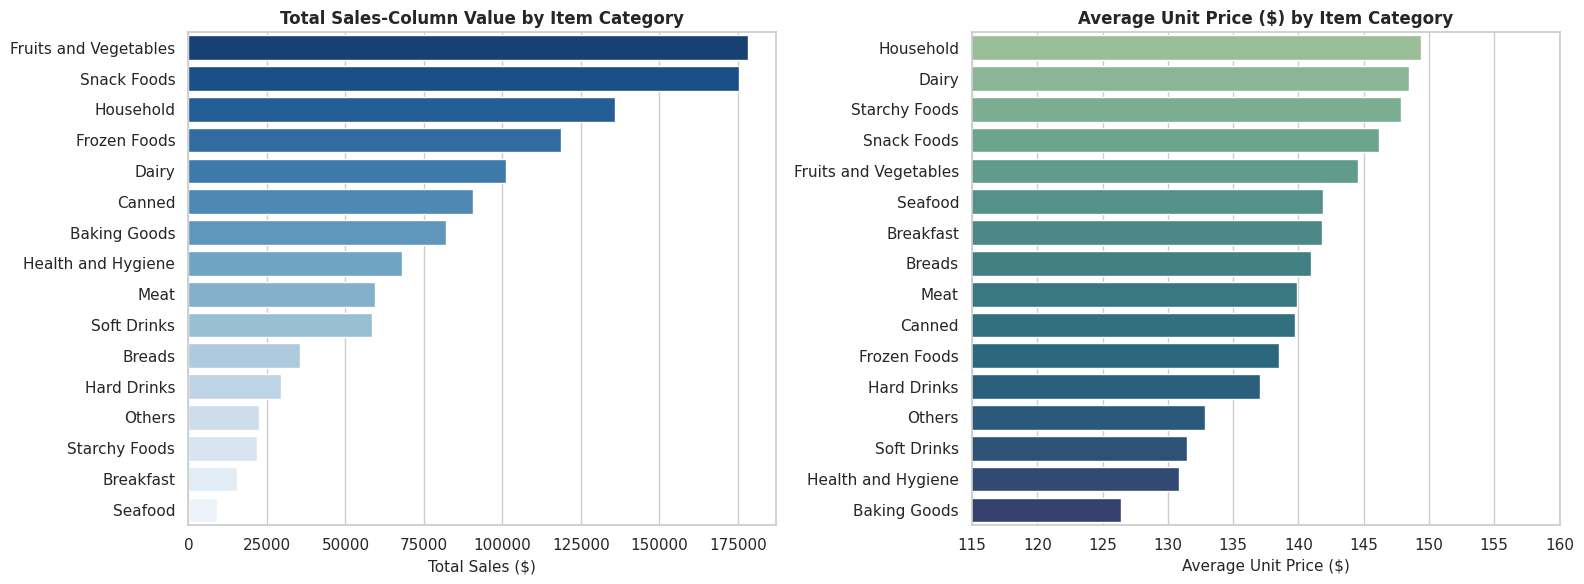

In [17]:
# Figure 6: Category Revenue & Price Drivers (2 Panels)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Total Sales by Category
sns.barplot(
    x=cat_sales['Total Sales ($)'],
    y=cat_sales.index,
    hue=cat_sales.index,
    palette='Blues_r',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Total Sales-Column Value by Item Category', fontweight='bold')
axes[0].set_xlabel('Total Sales ($)')
axes[0].set_ylabel('')

# Panel 2: Average Price per Record by Category
cat_sales_sorted_avg = cat_sales.sort_values(by='Avg Price/Record ($)', ascending=False)
sns.barplot(
    x=cat_sales_sorted_avg['Avg Price/Record ($)'],
    y=cat_sales_sorted_avg.index,
    hue=cat_sales_sorted_avg.index,
    palette='crest',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Average Unit Price ($) by Item Category', fontweight='bold')
axes[1].set_xlabel('Average Unit Price ($)')
axes[1].set_ylabel('')
axes[1].set_xlim(115, 160)

plt.tight_layout()
save_fig('06_category_sales_and_price.png')
plt.show()


**Task 3.1 Findings:**
- **Top Total Earners:** Fruits and Vegetables ($178,124.08, **14.82%**) and Snack Foods ($175,433.92, **14.60%**).
- **Dairy Performance:** Dairy accounts for **$101,276.46** (**8.43%** of total Sales-column value).
- **Top 5 Categories Cumulative Sales-Column Value:** Top 5 categories generate **$709,369.87 (59.03%)** of total Sales-column value.
- **Top 8 Categories Cumulative Sales-Column Value:** Top 8 categories account for **79.06%**.
- **Top 10 Categories Cumulative Sales-Column Value:** Top 10 categories account for **88.87%**.
- **Sales-Column Value Share by Fat Content:** Low Fat: **45.76%**, Regular: **35.40%**, Non-Edible: **18.84%**.
- **Average Price by Category:** Household ($149.44) and Dairy ($148.50) have higher unit prices; Baking Goods ($126.43) is lowest.

---
### Task 3.2: Outlet Attributes and Sales Impact
We examine store performance across format, tier, size, and store identifier.


In [18]:
outlet_perf = clean_df.groupby('Outlet Identifier').agg(
    Type=('Outlet Type', 'first'),
    Tier=('Outlet Location Type', 'first'),
    Size=('Outlet Size', 'first'),
    Age=('Outlet Age', 'first'),
    SKUs=('Item Identifier', 'count'),
    Total_Sales=('Sales', 'sum'),
    Avg_Sales=('Sales', 'mean')
).reset_index()

print("STORE-LEVEL PERFORMANCE SUMMARY:")
print(outlet_perf.to_string(index=False))


STORE-LEVEL PERFORMANCE SUMMARY:
Outlet Identifier              Type   Tier    Size  Age  SKUs  Total_Sales  Avg_Sales
           OUT010     Grocery Store Tier 3 Unknown   15   555   78131.5666 140.777597
           OUT013 Supermarket Type1 Tier 3    High   12   932  131809.0156 141.425982
           OUT017 Supermarket Type1 Tier 2 Unknown    6   926  129103.9604 139.421124
           OUT018 Supermarket Type2 Tier 3  Medium    4   928  131477.7764 141.678638
           OUT019     Grocery Store Tier 1   Small    8   528   73807.5824 139.787088
           OUT027 Supermarket Type3 Tier 3  Medium    8   935  130714.6746 139.801791
           OUT035 Supermarket Type1 Tier 2   Small    9   930  133103.9070 143.122481
           OUT045 Supermarket Type1 Tier 2 Unknown   11   929  130942.7802 140.950248
           OUT046 Supermarket Type1 Tier 1   Small   10   930  132113.3698 142.057387
           OUT049 Supermarket Type1 Tier 1  Medium   14   930  130476.8598 140.297699


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


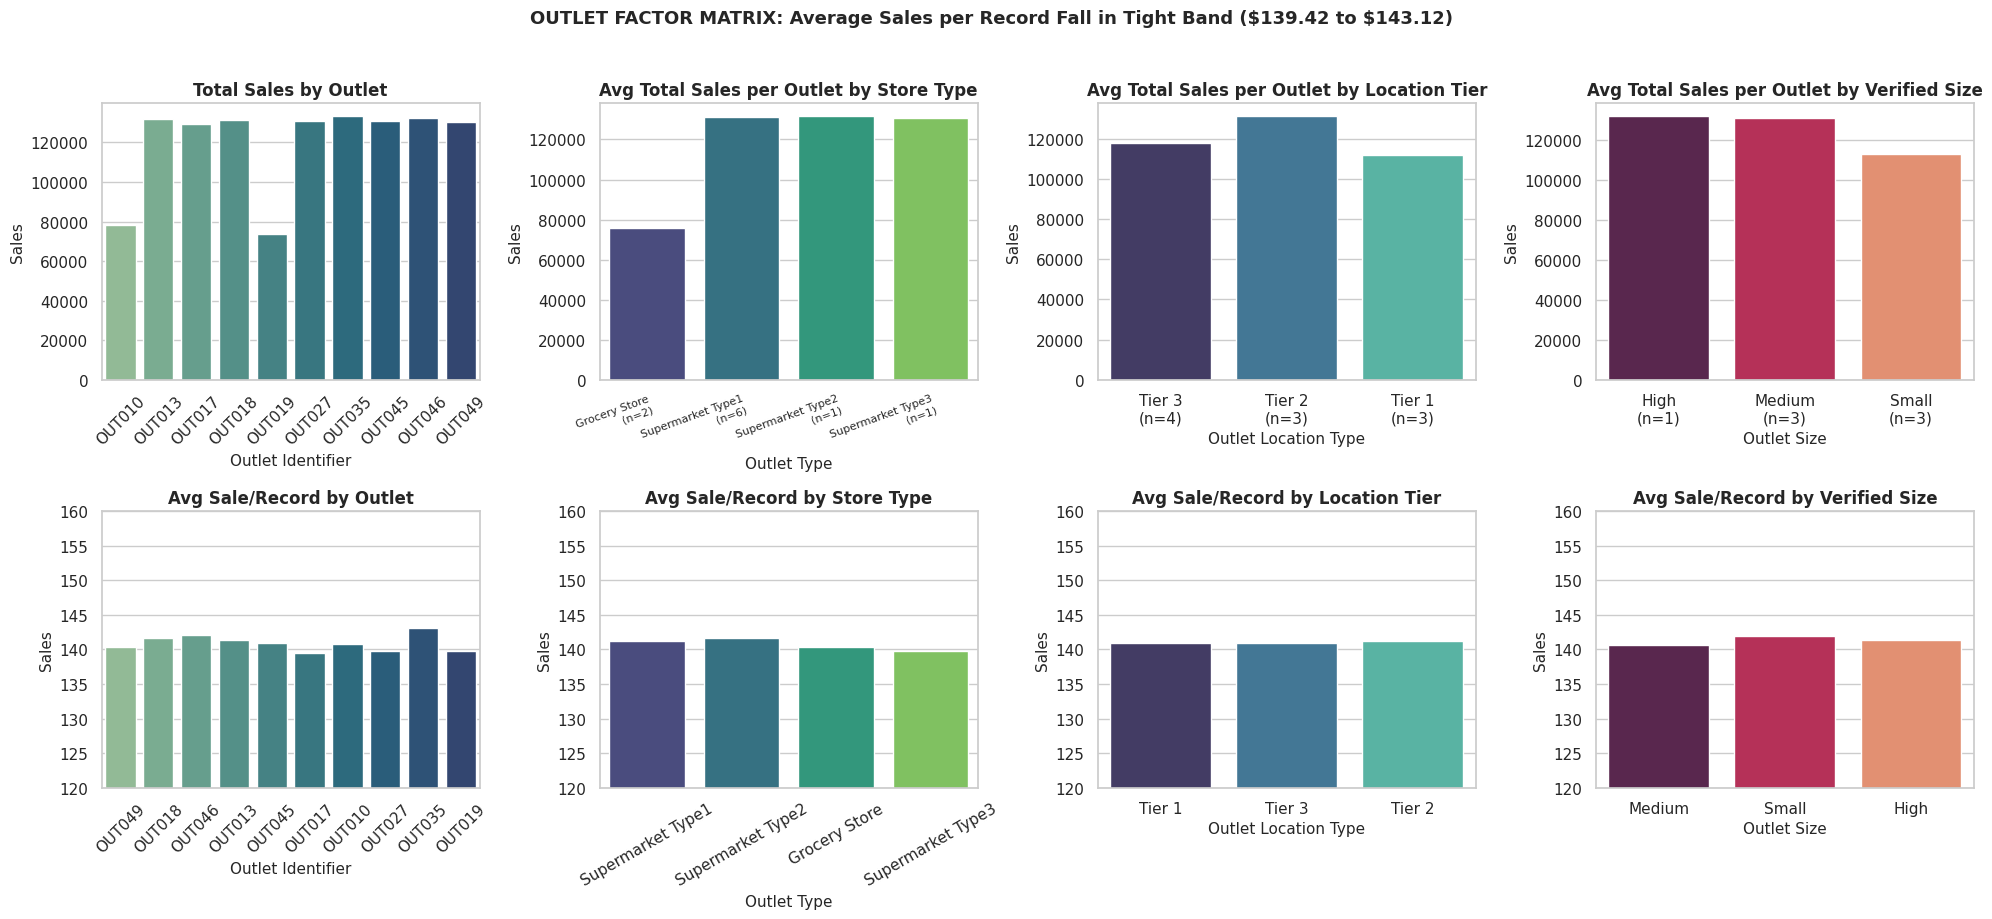

In [19]:
# Figure 7: 2x4 Outlet Factor Matrix (8 Panels in 1 Figure)
# Top row    : average TOTAL SALES PER OUTLET (n = number of outlets in the group). A raw group total mostly
#              reflects how many outlets the group has, so groups are compared per outlet.
# Bottom row : average Sales per record (value per item), which shows the parity between outlets.
out_min_val = clean_df.groupby('Outlet Identifier')['Sales'].mean().min()
out_max_val = clean_df.groupby('Outlet Identifier')['Sales'].mean().max()

outlet_totals = clean_df.groupby(['Outlet Identifier', 'Outlet Type', 'Outlet Location Type', 'Outlet Size'],
                                 as_index=False)['Sales'].sum()

def add_n_label(df, col):
    """Category name plus the number of outlets in that group, e.g. 'Grocery Store (n=2)'."""
    n = df.groupby(col)['Outlet Identifier'].nunique()
    return df[col].map(lambda v: f"{v}\n(n={n[v]})")

known_totals = outlet_totals[outlet_totals['Outlet Size'] != 'Unknown'].copy()
outlet_totals['Type label'] = add_n_label(outlet_totals, 'Outlet Type')
outlet_totals['Tier label'] = add_n_label(outlet_totals, 'Outlet Location Type')
known_totals['Size label'] = add_n_label(known_totals, 'Outlet Size')
known_sizes = clean_df[clean_df['Outlet Size'] != 'Unknown']

fig, axes = plt.subplots(2, 4, figsize=(20, 9))

# Row 1: total Sales per outlet
sns.barplot(x='Outlet Identifier', y='Sales', data=outlet_totals, errorbar=None, hue='Outlet Identifier', palette='crest', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Total Sales by Outlet', fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45)

sns.barplot(x='Type label', y='Sales', data=outlet_totals, estimator=np.mean, errorbar=None, hue='Type label', palette='viridis', legend=False, ax=axes[0, 1])
axes[0, 1].set_title('Avg Total Sales per Outlet by Store Type', fontweight='bold')
axes[0, 1].set_xlabel('Outlet Type')
plt.setp(axes[0, 1].get_xticklabels(), rotation=20, ha='right', rotation_mode='anchor', fontsize=8)

sns.barplot(x='Tier label', y='Sales', data=outlet_totals, estimator=np.mean, errorbar=None, hue='Tier label', palette='mako', legend=False, ax=axes[0, 2])
axes[0, 2].set_title('Avg Total Sales per Outlet by Location Tier', fontweight='bold')
axes[0, 2].set_xlabel('Outlet Location Type')

sns.barplot(x='Size label', y='Sales', data=known_totals, estimator=np.mean, errorbar=None, hue='Size label', palette='rocket', legend=False, ax=axes[0, 3])
axes[0, 3].set_title('Avg Total Sales per Outlet by Verified Size', fontweight='bold')
axes[0, 3].set_xlabel('Outlet Size')

# Row 2: Average Sales per Record (Demonstrating Parity)
sns.barplot(x='Outlet Identifier', y='Sales', data=clean_df, estimator=np.mean, errorbar=None, hue='Outlet Identifier', palette='crest', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Avg Sale/Record by Outlet', fontweight='bold')
axes[1, 0].set_ylim(120, 160)
axes[1, 0].tick_params(axis='x', rotation=45)

sns.barplot(x='Outlet Type', y='Sales', data=clean_df, estimator=np.mean, errorbar=None, hue='Outlet Type', palette='viridis', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Avg Sale/Record by Store Type', fontweight='bold')
axes[1, 1].set_ylim(120, 160)
axes[1, 1].tick_params(axis='x', rotation=30)

sns.barplot(x='Outlet Location Type', y='Sales', data=clean_df, estimator=np.mean, errorbar=None, hue='Outlet Location Type', palette='mako', legend=False, ax=axes[1, 2])
axes[1, 2].set_title('Avg Sale/Record by Location Tier', fontweight='bold')
axes[1, 2].set_ylim(120, 160)

sns.barplot(x='Outlet Size', y='Sales', data=known_sizes, estimator=np.mean, errorbar=None, hue='Outlet Size', palette='rocket', legend=False, ax=axes[1, 3])
axes[1, 3].set_title('Avg Sale/Record by Verified Size', fontweight='bold')
axes[1, 3].set_ylim(120, 160)

plt.suptitle(f"OUTLET FACTOR MATRIX: Average Sales per Record Fall in Tight Band (\\${out_min_val:.2f} to \\${out_max_val:.2f})", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig('07_outlet_factor_matrix.png')
plt.show()


In [20]:
# Task 3.2: Outlet Size compared fairly (per record and per store).
# OUT010, OUT017 and OUT045 are 'Unknown' (inconsistent size labels) and are left out.
size_view = known_sizes.groupby('Outlet Size').agg(
    Stores=('Outlet Identifier', 'nunique'),
    Records=('Sales', 'count'),
    Total_Sales=('Sales', 'sum'),
    Avg_Sales_per_Record=('Sales', 'mean'))
size_view['Sales_per_Store'] = (size_view['Total_Sales'] / size_view['Stores']).round(0)
print("OUTLET SIZE (7 outlets with one consistent size):")
print(size_view.round(2).to_string())
print()
print(known_sizes.groupby(['Outlet Size', 'Outlet Type'])['Outlet Identifier'].unique().to_string())

small_super = known_sizes[(known_sizes['Outlet Size'] == 'Small') & (known_sizes['Outlet Type'] != 'Grocery Store')]
print()
print("Small supermarkets only, Sales per store:", round(small_super['Sales'].sum() / small_super['Outlet Identifier'].nunique()))


OUTLET SIZE (7 outlets with one consistent size):
             Stores  Records  Total_Sales  Avg_Sales_per_Record  Sales_per_Store
Outlet Size                                                                     
High              1      932    131809.02                141.43         131809.0
Medium            3     2793    392669.31                140.59         130890.0
Small             3     2388    339024.86                141.97         113008.0

Outlet Size  Outlet Type      
High         Supermarket Type1            [OUT013]
Medium       Supermarket Type1            [OUT049]
             Supermarket Type2            [OUT018]
             Supermarket Type3            [OUT027]
Small        Grocery Store                [OUT019]
             Supermarket Type1    [OUT046, OUT035]

Small supermarkets only, Sales per store: 132609


**Task 3.2 Findings & Store Economics:**
- **Average Sales Band:** Across all 10 outlets, mean sales fall in an extremely narrow band of **$139.42 to $143.12**.
- **Store Format Aggregates:**
  - Supermarket Type 1: **$787,549.89** across 6 outlets ($131,258.32/outlet).
  - Supermarket Type 2: **$131,477.78** (1 outlet).
  - Supermarket Type 3: **$130,714.67** (1 outlet).
  - Grocery Store: **$151,939.15** across 2 outlets (**$75,969.57/outlet**, ~42% lower).
- **Location Tier Aggregates:**
  - Tier 3: **$472,133.03** ($118,033.26/outlet across 4 stores).
  - Tier 2: **$393,150.65** ($131,050.22/outlet across 3 stores).
  - Tier 1: **$336,397.81** ($112,132.60/outlet across 3 stores).

---
### Task 3.3: Statistical Relationship Testing & Variance Decomposition
We perform:
1. Variance decomposition to quantify what `Sales` represents.
2. Pearson correlation testing on continuous variables.
3. Kruskal-Wallis non-parametric tests across categories and outlet types.
- **Outlet Size** (OUT010, OUT017 and OUT045 are left out because their size is recorded inconsistently):
  - Average Sales per record is the same across sizes: High 141.43, Medium 140.59, Small 141.97.
  - Per store: High 131,809 (a single store, OUT013), Medium 130,890, Small 113,008.
  - Small looks lower only because it includes the Grocery Store OUT019. Its two Small supermarkets (OUT035 and OUT046) average about 132,609 per store, so size shows no clear effect.
- **Reading Figure 7:** the top row shows the average total per outlet, with the number of outlets in each group (n), so groups with different numbers of stores compare fairly.


In [21]:
# Variance Decomposition of Sales
grand_mean = clean_df['Sales'].mean()
ss_total = ((clean_df['Sales'] - grand_mean) ** 2).sum()

sku_means = clean_df.groupby('Item Identifier')['Sales'].transform('mean')
ss_sku = ((sku_means - grand_mean) ** 2).sum()

outlet_means = clean_df.groupby('Outlet Identifier')['Sales'].transform('mean')
ss_outlet = ((outlet_means - grand_mean) ** 2).sum()

cat_means = clean_df.groupby('Item Type')['Sales'].transform('mean')
ss_cat = ((cat_means - grand_mean) ** 2).sum()

print("=" * 70)
print("VARIANCE DECOMPOSITION OF SALES (R-SQUARED):")
print("=" * 70)
print(f"Variance explained by Item Identifier (SKU)   : {ss_sku / ss_total * 100:.2f}% (R^2 = {ss_sku / ss_total:.4f})")
print(f"Variance explained by Category (Item Type)     : {ss_cat / ss_total * 100:.2f}% (R^2 = {ss_cat / ss_total:.4f})")
print(f"Variance explained by Outlet Identifier        : {ss_outlet / ss_total * 100:.2f}% (R^2 = {ss_outlet / ss_total:.4f})")
print(f"Mean within-SKU standard deviation of Sales    : ${clean_df.groupby('Item Identifier')['Sales'].std().mean():.2f}")
print(f"Overall standard deviation of Sales            : ${clean_df['Sales'].std():.2f}")

print("\n" + "=" * 70)
print("PEARSON CORRELATION TESTS (CLEANED DATA):")
print("=" * 70)
corr_results = {}
for col in ['Item Visibility', 'Item Weight', 'Rating', 'Outlet Age']:
    r, p = stats.pearsonr(clean_df[col], clean_df['Sales'])
    corr_results[col] = (r, p)
    print(f"Sales vs {col:<15}: r = {r:+.4f}, p = {p:.4e}")

# Kruskal-Wallis Non-Parametric Tests
cat_groups = [group['Sales'].values for _, group in clean_df.groupby('Item Type')]
kw_cat_stat, kw_cat_p = stats.kruskal(*cat_groups)

type_groups = [group['Sales'].values for _, group in clean_df.groupby('Outlet Type')]
kw_type_stat, kw_type_p = stats.kruskal(*type_groups)

print("\n" + "=" * 70)
print("KRUSKAL-WALLIS HYPOTHESIS TEST RESULTS:")
print("=" * 70)
print(f"Across 16 Categories  : H = {kw_cat_stat:.2f}, p = {kw_cat_p:.2e} (Statistically Significant)")
print(f"Across 4 Outlet Types : H = {kw_type_stat:.2f}, p = {kw_type_p:.3f} (Not Significant)")


VARIANCE DECOMPOSITION OF SALES (R-SQUARED):
Variance explained by Item Identifier (SKU)   : 99.97% (R^2 = 0.9997)
Variance explained by Category (Item Type)     : 1.25% (R^2 = 0.0125)
Variance explained by Outlet Identifier        : 0.03% (R^2 = 0.0003)
Mean within-SKU standard deviation of Sales    : $1.15
Overall standard deviation of Sales            : $62.28

PEARSON CORRELATION TESTS (CLEANED DATA):
Sales vs Item Visibility: r = -0.0060, p = 5.8276e-01
Sales vs Item Weight    : r = +0.0260, p = 1.6502e-02
Sales vs Rating         : r = +0.0113, p = 2.9565e-01
Sales vs Outlet Age     : r = +0.0007, p = 9.5184e-01

KRUSKAL-WALLIS HYPOTHESIS TEST RESULTS:
Across 16 Categories  : H = 107.30, p = 5.31e-16 (Statistically Significant)
Across 4 Outlet Types : H = 0.37, p = 0.947 (Not Significant)


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


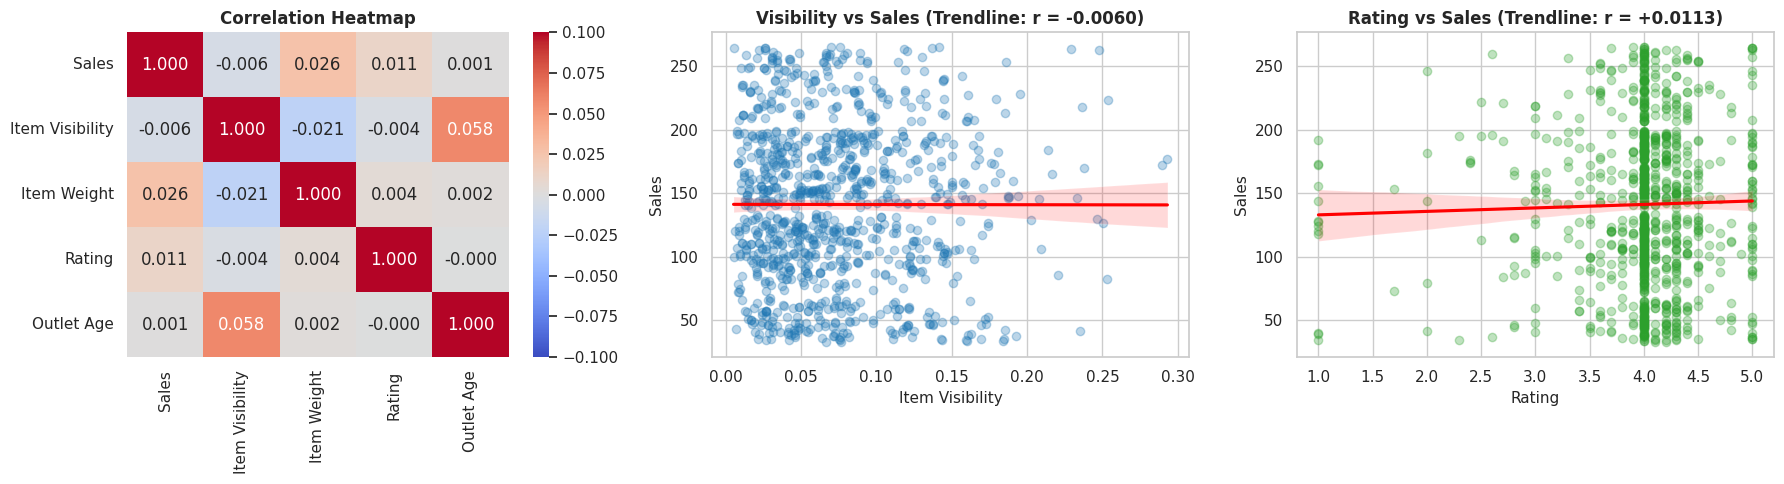

In [22]:
# Figure 8: Correlation Heatmap and Scatter Trendlines (3 Panels)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

corr_m = clean_df[['Sales', 'Item Visibility', 'Item Weight', 'Rating', 'Outlet Age']].corr()
sns.heatmap(corr_m, annot=True, cmap='coolwarm', fmt='.3f', vmin=-0.1, vmax=0.1, ax=axes[0], cbar=True)
axes[0].set_title('Correlation Heatmap', fontweight='bold')

sample_df = clean_df.sample(n=1000, random_state=42)
r_vis_val = corr_results['Item Visibility'][0]
sns.regplot(x='Item Visibility', y='Sales', data=sample_df, ax=axes[1],
            scatter_kws={'alpha': 0.3, 'color': '#1f77b4'}, line_kws={'color': 'red'})
axes[1].set_title(f'Visibility vs Sales (Trendline: r = {r_vis_val:+.4f})', fontweight='bold')

r_rat_val = corr_results['Rating'][0]
sns.regplot(x='Rating', y='Sales', data=sample_df, ax=axes[2],
            scatter_kws={'alpha': 0.3, 'color': '#2ca02c'}, line_kws={'color': 'red'})
axes[2].set_title(f'Rating vs Sales (Trendline: r = {r_rat_val:+.4f})', fontweight='bold')

plt.tight_layout()
save_fig('08_correlations.png')
plt.show()


**Task 3.3 Findings & Reframed Interpretation:**
1. **Sales is consistent with / behaves like Item Retail Price (MRP):**  
   `Item Identifier` accounts for **99.97%** of the variance in `Sales`. The standard deviation within a SKU is just **$1.15**, compared to **$62.28** overall.
2. **Kruskal-Wallis Category Effect:**  
   $H = 107.30, p = 5.31 \times 10^{-16}$. This test detects **category-level price variations** (Household and Dairy have higher unit prices than Baking Goods and Soft Drinks), which account for 1.25% of total price variance.
3. **Outlet Format Null Result:**  
   $H = 0.37, p = 0.947$. Outlet types exhibit identical price distributions because each store samples from the same overall catalogue.
4. **Correlation Results:**  
   - Visibility vs Sales: $r = -0.0060, p = 0.5828$ (No relationship)
   - Weight vs Sales: $r = +0.0260, p = 0.0165$ (Negligible effect)
   - Rating vs Sales: $r = +0.0113, p = 0.2957$ (No relationship)
   - Outlet Age vs Sales: $r = +0.0007, p = 0.9518$ (No relationship)

---
### Task 3.4: Cohort Comparison (Top 25% vs Bottom 25%)
We split records by sales quartiles into Top 25% (≥ $185.64) and Bottom 25% (≤ $93.83).


In [23]:
q1_cut = clean_df['Sales'].quantile(0.25)
q3_cut = clean_df['Sales'].quantile(0.75)

clean_df['Cohort'] = 'Middle 50%'
clean_df.loc[clean_df['Sales'] <= q1_cut, 'Cohort'] = 'Bottom 25% (Low Sales)'
clean_df.loc[clean_df['Sales'] >= q3_cut, 'Cohort'] = 'Top 25% (High Sales)'

cohort_sub = clean_df[clean_df['Cohort'] != 'Middle 50%']
cohort_metrics = cohort_sub.groupby('Cohort').agg(
    Record_Count=('Sales', 'count'),
    Mean_Sales=('Sales', 'mean'),
    Mean_Visibility=('Item Visibility', 'mean'),
    Mean_Weight=('Item Weight', 'mean'),
    Mean_Rating=('Rating', 'mean'),
    Mean_Outlet_Age=('Outlet Age', 'mean')
)

print("COHORT PROFILING: TOP 25% vs BOTTOM 25%:")
print(cohort_metrics.round(3).to_string())


COHORT PROFILING: TOP 25% vs BOTTOM 25%:
                        Record_Count  Mean_Sales  Mean_Visibility  Mean_Weight  Mean_Rating  Mean_Outlet_Age
Cohort                                                                                                      
Bottom 25% (Low Sales)          2131      61.938            0.071       12.805        3.965            9.535
Top 25% (High Sales)            2131     222.805            0.071       13.067        3.965            9.537


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


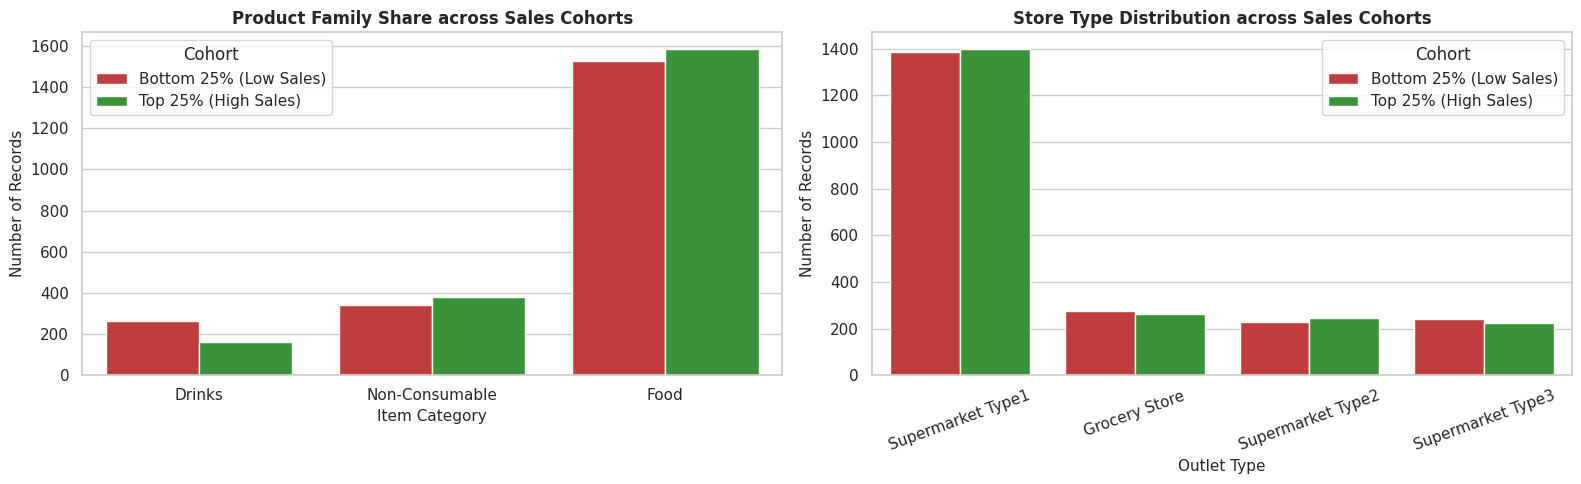

In [24]:
# Figure 9: Cohort Comparison Distributions (2 Panels)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(
    x='Item Category', 
    hue='Cohort', 
    data=cohort_sub, 
    palette=['#d62728', '#2ca02c'], 
    ax=axes[0]
)
axes[0].set_title('Product Family Share across Sales Cohorts', fontweight='bold')
axes[0].set_ylabel('Number of Records')

sns.countplot(
    x='Outlet Type', 
    hue='Cohort', 
    data=cohort_sub, 
    palette=['#d62728', '#2ca02c'], 
    ax=axes[1]
)
axes[1].set_title('Store Type Distribution across Sales Cohorts', fontweight='bold')
axes[1].set_ylabel('Number of Records')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
save_fig('09_cohort_product_family_and_store_type.png')
plt.show()


In [25]:
# Task 3.4 (products): which product types are over- or under-represented in each cohort?
top_label, bottom_label = 'Top 25% (High Sales)', 'Bottom 25% (Low Sales)'

def cohort_mix(col):
    """Share (%) of each group inside the Top and Bottom cohorts, and the gap between them in percentage points."""
    share = pd.crosstab(cohort_sub[col], cohort_sub['Cohort'], normalize='columns') * 100
    mix = pd.DataFrame({'Bottom 25% share (%)': share[bottom_label],
                        'Top 25% share (%)': share[top_label]})
    mix['Top - Bottom (pp)'] = mix['Top 25% share (%)'] - mix['Bottom 25% share (%)']
    return mix.sort_values('Top - Bottom (pp)', ascending=False)

type_mix = cohort_mix('Item Type').join(clean_df.groupby('Item Type')['Sales'].mean().rename('Avg Sales (all records)'))
family_mix = cohort_mix('Item Category')

print("PRODUCT TYPE MIX, TOP 25% vs BOTTOM 25% OF RECORDS (pp = percentage points):")
print(type_mix.round(2).to_string())
print()
print("PRODUCT FAMILY MIX:")
print(family_mix.round(2).to_string())
print()
print(f"Most over-represented in the Top cohort   : {type_mix.index[0]} ({type_mix['Top - Bottom (pp)'].iloc[0]:+.2f} pp)")
print(f"Most over-represented in the Bottom cohort: {type_mix.index[-1]} ({type_mix['Top - Bottom (pp)'].iloc[-1]:+.2f} pp)")


PRODUCT TYPE MIX, TOP 25% vs BOTTOM 25% OF RECORDS (pp = percentage points):
                       Bottom 25% share (%)  Top 25% share (%)  Top - Bottom (pp)  Avg Sales (all records)
Item Type                                                                                                 
Household                              7.98              11.97               3.99                   149.42
Snack Foods                           10.75              14.12               3.38                   146.19
Fruits and Vegetables                 13.00              16.28               3.28                   144.58
Dairy                                  9.15              10.56               1.41                   148.50
Meat                                   4.36               4.83               0.47                   139.88
Starchy Foods                          1.97               2.16               0.19                   147.84
Breads                                 3.10               3.28     

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


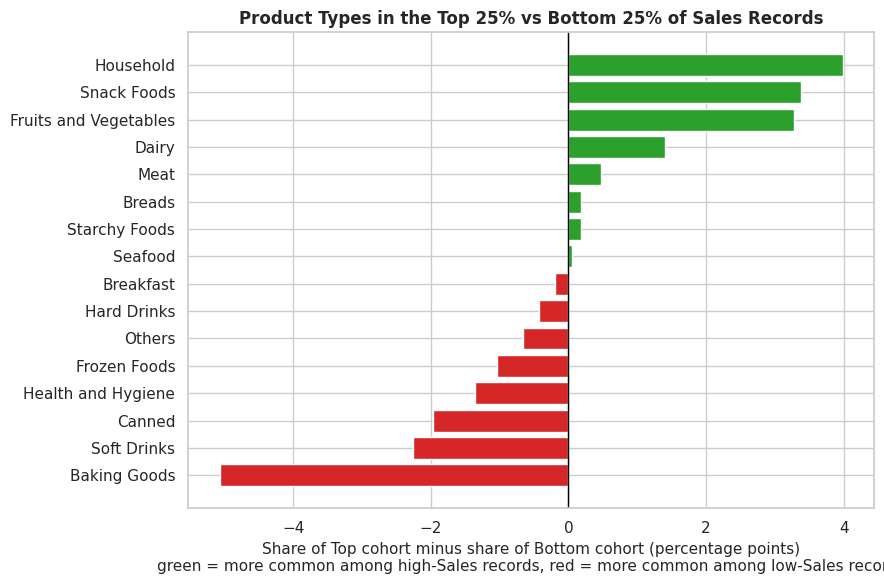

In [26]:
# Figure 9b: product-type gap between the Top and Bottom cohorts
gap = type_mix['Top - Bottom (pp)'].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(gap.index, gap.values, color=['#2ca02c' if v > 0 else '#d62728' for v in gap.values])
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Product Types in the Top 25% vs Bottom 25% of Sales Records', fontweight='bold')
ax.set_xlabel('Share of Top cohort minus share of Bottom cohort (percentage points)\n'
              'green = more common among high-Sales records, red = more common among low-Sales records')
plt.tight_layout()
save_fig('09b_cohort_product_type_gap.png')
plt.show()


In [27]:
# Task 3.4 (outlets): compare higher- and lower-performing outlets
outlet_rank = clean_df.groupby('Outlet Identifier').agg(
    Type=('Outlet Type', 'first'),
    Tier=('Outlet Location Type', 'first'),
    Listings=('Item Identifier', 'count'),
    Total_Sales=('Sales', 'sum'),
    Avg_Sales_per_Record=('Sales', 'mean')
).sort_values('Total_Sales', ascending=False)

best = outlet_rank.iloc[0]
outlet_rank['Total vs best (%)'] = (outlet_rank['Total_Sales'] / best['Total_Sales'] - 1) * 100
outlet_rank['Listings vs best (%)'] = (outlet_rank['Listings'] / best['Listings'] - 1) * 100
outlet_rank['Avg/record vs best (%)'] = (outlet_rank['Avg_Sales_per_Record'] / best['Avg_Sales_per_Record'] - 1) * 100

print("OUTLETS RANKED BY TOTAL SALES (best first):")
print(outlet_rank.round(2).to_string())
print()
for outlet_id in outlet_rank.index[-2:]:
    r = outlet_rank.loc[outlet_id]
    print(f"{outlet_id} vs best ({outlet_rank.index[0]}): total {r['Total vs best (%)']:+.1f}% | "
          f"items listed {r['Listings vs best (%)']:+.1f}% | average Sales per record {r['Avg/record vs best (%)']:+.1f}%")


OUTLETS RANKED BY TOTAL SALES (best first):
                                Type    Tier  Listings  Total_Sales  Avg_Sales_per_Record  Total vs best (%)  Listings vs best (%)  Avg/record vs best (%)
Outlet Identifier                                                                                                                                         
OUT035             Supermarket Type1  Tier 2       930    133103.91                143.12               0.00                  0.00                    0.00
OUT046             Supermarket Type1  Tier 1       930    132113.37                142.06              -0.74                  0.00                   -0.74
OUT013             Supermarket Type1  Tier 3       932    131809.02                141.43              -0.97                  0.22                   -1.19
OUT018             Supermarket Type2  Tier 3       928    131477.78                141.68              -1.22                 -0.22                   -1.01
OUT045             Superma

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


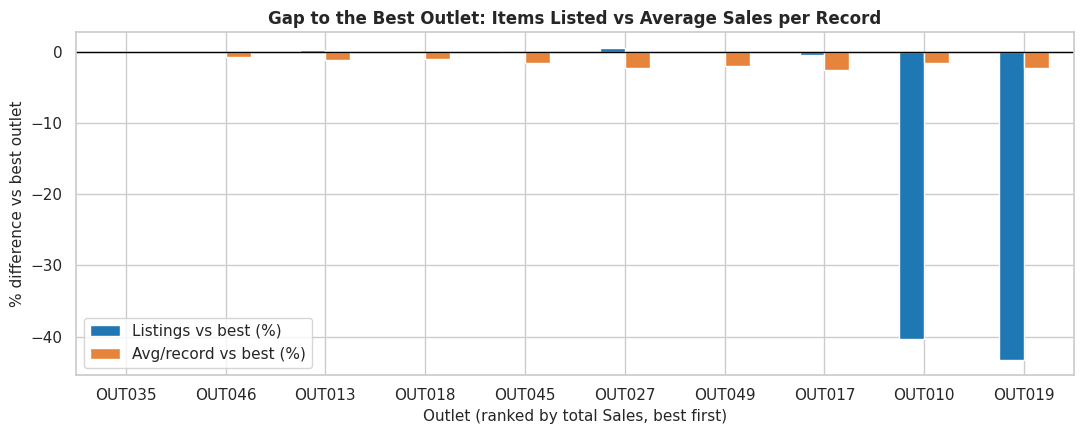

In [28]:
# Figure 9c: is the gap to the best outlet about how many items it lists, or about the value per item?
ax = outlet_rank[['Listings vs best (%)', 'Avg/record vs best (%)']].plot(kind='bar', figsize=(11, 4.5), color=['#1f77b4', '#e6843b'])
ax.axhline(0, color='black', linewidth=1)
ax.set_title('Gap to the Best Outlet: Items Listed vs Average Sales per Record', fontweight='bold')
ax.set_ylabel('% difference vs best outlet')
ax.set_xlabel('Outlet (ranked by total Sales, best first)')
plt.xticks(rotation=0)
plt.tight_layout()
save_fig('09c_outlet_gap_decomposition.png')
plt.show()


**Task 3.4 Findings:**

*Products: Top 25% vs Bottom 25% of records*
- The two cohorts look almost the same on the other attributes: mean Item Visibility is 0.071 in both, mean Outlet Age is 9.54 years in both, mean Rating is 3.965 in both, and mean Item Weight is 13.07 (Top) vs 12.81 (Bottom), with the unit not stated in the data.
- They differ by product type. The table below Figure 9 and Figure 9b show each type's share of the Top and Bottom cohorts. The two lines printed under the table name the most over- and under-represented types: compare them with the Avg Sales column. Because Sales behaves like an item price (Task 3.3), this separates higher-priced from lower-priced product types, not faster-selling from slower-selling ones.

*Outlets: higher- vs lower-performing*
- Ranked by total Sales, the best outlets are OUT035 (133,104), OUT046 (132,113) and OUT013 (131,809). The lowest are the two Grocery Stores: OUT019 (73,808, 44.5% below the best) and OUT010 (78,132, 41.3% below). The next lowest, OUT017, is only 3.0% below the best.
- The gap is about how many items an outlet lists, not the value per item: OUT019 lists 43.2% fewer items than OUT035 but its average Sales per record is only 2.3% lower (OUT010: 40.3% fewer items, 1.6% lower average).
- Figure 9c shows this for every outlet. "Higher-performing" here means "lists more items", not "sells more units".


In [29]:
sku_rankings = clean_df.groupby(['Item Identifier', 'Item Type', 'Item Category']).agg(
    Outlets_Stocked=('Outlet Identifier', 'count'),
    Mean_Sales=('Sales', 'mean'),
    Total_Sales=('Sales', 'sum')
).reset_index()

print("CORRELATION BETWEEN OUTLET STOCK COUNT AND TOTAL SKU SALES:")
print(f"r = {sku_rankings['Total_Sales'].corr(sku_rankings['Outlets_Stocked']):.4f} (Distribution breadth drives total SKU ranking)")

print("\nTOP 10 SKUS BY MEAN PRICE (UNIT VALUE):")
print(sku_rankings.sort_values(by='Mean_Sales', ascending=False).head(10).to_string(index=False))

print("\nTOP 10 SKUS BY TOTAL ACCUMULATED SALES:")
print(sku_rankings.sort_values(by='Total_Sales', ascending=False).head(10).to_string(index=False))

# Category-Level Pareto Calculation
pareto_s = clean_df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)
pareto_df = pd.DataFrame({'Total_Sales': pareto_s})
pareto_df['Cumulative_Sales'] = pareto_df['Total_Sales'].cumsum()
pareto_df['Cumulative_Share_%'] = (pareto_df['Cumulative_Sales'] / pareto_df['Total_Sales'].sum() * 100).round(2)

top5_sales_val = pareto_df.head(5)['Total_Sales'].sum()
top5_sales_pct = (top5_sales_val / clean_df['Sales'].sum()) * 100

print("\nPARETO DISTRIBUTION TABLE (CUMULATIVE SALES-COLUMN VALUE):")
print(pareto_df.to_string())


CORRELATION BETWEEN OUTLET STOCK COUNT AND TOTAL SKU SALES:
r = 0.5259 (Distribution breadth drives total SKU ranking)

TOP 10 SKUS BY MEAN PRICE (UNIT VALUE):
Item Identifier          Item Type  Item Category  Outlets_Stocked  Mean_Sales  Total_Sales
          FDR25             Canned           Food                5  265.468400    1327.3420
          NCS29 Health and Hygiene Non-Consumable                6  265.455067    1592.7304
          FDK51              Dairy           Food                7  265.416971    1857.9188
          FDS13             Canned           Food                7  265.302686    1857.1188
          FDL58        Snack Foods           Food                8  263.956800    2111.6544
          FDI15              Dairy           Food                6  263.938400    1583.6304
          FDV49             Canned           Food                6  263.855933    1583.1356
          FDB15              Dairy           Food                7  263.813943    1846.6976
          NC

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial


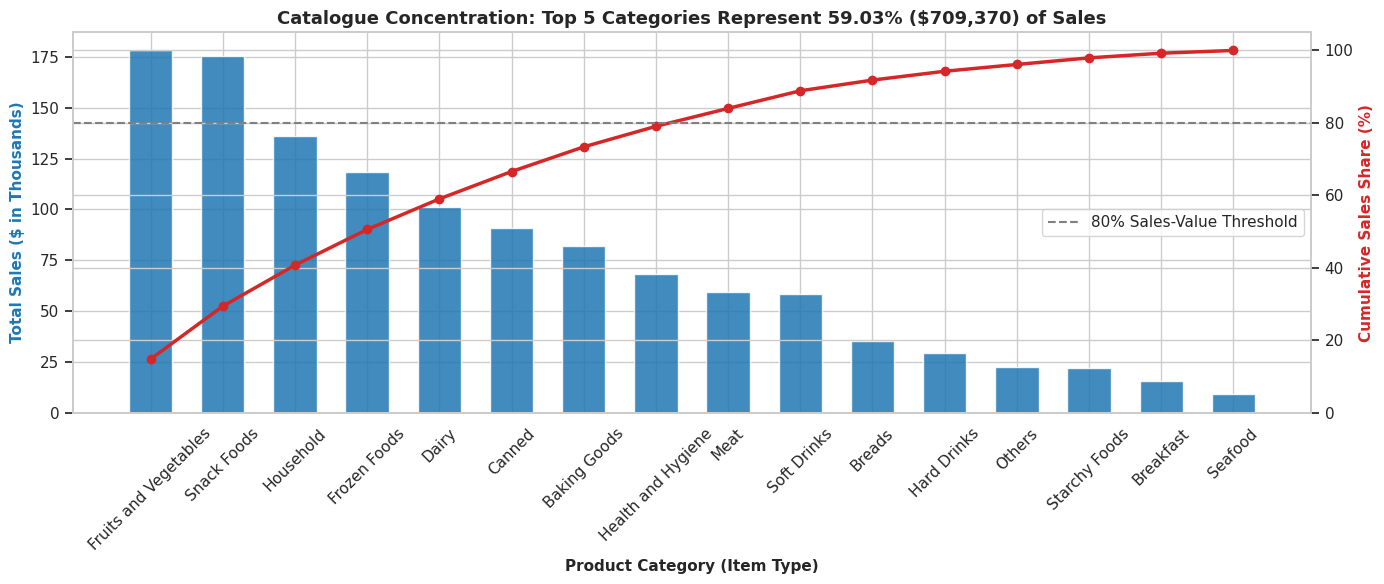

In [30]:
# Figure 10: Pareto Catalogue Concentration (1 Panel)
fig, ax1 = plt.subplots(figsize=(14, 6))

ax2 = ax1.twinx()
ax1.bar(pareto_df.index, pareto_df['Total_Sales'] / 1000, color='#1f77b4', alpha=0.85, width=0.6)
ax2.plot(pareto_df.index, pareto_df['Cumulative_Share_%'], color='#d62728', marker='o', linewidth=2.5)

ax1.set_xlabel('Product Category (Item Type)', fontweight='bold')
ax1.set_ylabel('Total Sales ($ in Thousands)', color='#1f77b4', fontweight='bold')
ax2.set_ylabel('Cumulative Sales Share (%)', color='#d62728', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax2.axhline(80, color='gray', linestyle='--', linewidth=1.5, label='80% Sales-Value Threshold')
ax2.set_ylim(0, 105)
ax2.legend(loc='center right')

plt.title(f'Catalogue Concentration: Top 5 Categories Represent {top5_sales_pct:.2f}% (${top5_sales_val:,.0f}) of Sales', fontweight='bold', fontsize=13)
plt.tight_layout()
save_fig('10_pareto_categories.png')
plt.show()


**Task 4.1 Findings:**
- Top 5 categories generate **$709,369.87 (59.03%)** of total Sales-column value.
- Top 8 categories account for **79.06%**.
- Top 10 categories account for **88.87%**.

---
### Task 4.2: Outlet & Location Fair Comparison (Composition Effect & Store Format Confounding)
We normalize by calculating sales per outlet.


In [31]:
tier_norm = clean_df.groupby('Outlet Location Type').agg(
    Total_Sales=('Sales', 'sum'),
    Outlet_Count=('Outlet Identifier', 'nunique')
).assign(Sales_Per_Outlet=lambda x: x['Total_Sales'] / x['Outlet_Count']).sort_values(by='Sales_Per_Outlet', ascending=False)

type_norm = clean_df.groupby('Outlet Type').agg(
    Total_Sales=('Sales', 'sum'),
    Outlet_Count=('Outlet Identifier', 'nunique')
).assign(Sales_Per_Outlet=lambda x: x['Total_Sales'] / x['Outlet_Count']).sort_values(by='Sales_Per_Outlet', ascending=False)

print("=" * 70)
print("OVERALL SALES PER OUTLET BY LOCATION TIER:")
print("=" * 70)
print(tier_norm.round(2).to_string())

print("\n" + "=" * 70)
print("OVERALL SALES PER OUTLET BY STORE TYPE:")
print("=" * 70)
print(type_norm.round(2).to_string())

# Testing Supermarkets Only Across Tiers
supermarket_only = clean_df[clean_df['Outlet Type'] != 'Grocery Store']
sup_tier_norm = supermarket_only.groupby('Outlet Location Type').agg(
    Supermarket_Sales=('Sales', 'sum'),
    Supermarket_Count=('Outlet Identifier', 'nunique')
).assign(Sales_Per_Supermarket=lambda x: x['Supermarket_Sales'] / x['Supermarket_Count'])

print("\n" + "=" * 70)
print("STORE FORMAT COMPOSITION EFFECT PROOF: SUPERMARKET SALES PER STORE ACROSS TIERS:")
print("=" * 70)
print(sup_tier_norm.round(2).to_string())


OVERALL SALES PER OUTLET BY LOCATION TIER:
                      Total_Sales  Outlet_Count  Sales_Per_Outlet
Outlet Location Type                                             
Tier 2                  393150.65             3         131050.22
Tier 3                  472133.03             4         118033.26
Tier 1                  336397.81             3         112132.60

OVERALL SALES PER OUTLET BY STORE TYPE:
                   Total_Sales  Outlet_Count  Sales_Per_Outlet
Outlet Type                                                   
Supermarket Type2    131477.78             1         131477.78
Supermarket Type1    787549.89             6         131258.32
Supermarket Type3    130714.67             1         130714.67
Grocery Store        151939.15             2          75969.57

STORE FORMAT COMPOSITION EFFECT PROOF: SUPERMARKET SALES PER STORE ACROSS TIERS:
                      Supermarket_Sales  Supermarket_Count  Sales_Per_Supermarket
Outlet Location Type                        

**Task 4.2 Findings & The Tier 2 Resolution:**
- **The Tier 2 Illusion:** Overall, Tier 2 appears to lead at **$131,050.22/outlet** vs Tier 3 ($118,033.26) and Tier 1 ($112,132.60).
- **The True Driver (Composition Effect / Store Format Confounding):** Tier 2 contains **zero Grocery Stores** (all 3 are Supermarkets). Comparing overall tier averages conflates store format with geographic location.
- **When controlling for format (Supermarkets only):**
  - Tier 1 Supermarkets: **$131,295.11 / store**
  - Tier 2 Supermarkets: **$131,050.22 / store**
  - Tier 3 Supermarkets: **$131,333.82 / store**
- **Conclusion:** There is zero difference across tiers for supermarkets. Tier 2's apparent advantage is an artifact of having no smaller grocery store dragging down its average.

---
### Task 4.3: Opportunity Areas & Assortment Gap Analysis
We analyze why Grocery Stores earn $75,969.57 per store compared to ~$131,258 in Supermarket Type 1.


In [32]:
assortment_audit = clean_df.groupby(['Outlet Identifier', 'Outlet Type']).agg(
    SKUs_Stocked=('Item Identifier', 'count'),
    Total_Sales=('Sales', 'sum'),
    Sales_Per_SKU=('Sales', 'mean')
).reset_index()

print("STORE ASSORTMENT BREADTH AND SALES VALUE PER SKU:")
print(assortment_audit.round(2).to_string(index=False))

# Grocery store catalog quality check
groc_data = clean_df[clean_df['Outlet Type'] == 'Grocery Store']
sup_data = clean_df[clean_df['Outlet Type'] != 'Grocery Store']

groc_mean_pr = groc_data['Sales'].mean()
sup_mean_pr = sup_data['Sales'].mean()

print("\n" + "=" * 70)
print("GROCERY STORE ASSORTMENT QUALITY CHECK:")
print("=" * 70)
print(f"Grocery Store Distinct SKUs Stocked: {groc_data['Item Identifier'].nunique():,} distinct SKUs")
print(f"Grocery Store Mean Sale per Item    : ${groc_mean_pr:.2f}")
print(f"Supermarket Mean Sale per Item      : ${sup_mean_pr:.2f} (Nearly Identical)")
print("\nCategory Mix Comparison (% of items):")
comp_mix = pd.DataFrame({
    'Grocery Store (%)': (groc_data['Item Type'].value_counts(normalize=True) * 100).round(2),
    'Supermarket (%)': (sup_data['Item Type'].value_counts(normalize=True) * 100).round(2)
})
print(comp_mix.head(6).to_string())


STORE ASSORTMENT BREADTH AND SALES VALUE PER SKU:
Outlet Identifier       Outlet Type  SKUs_Stocked  Total_Sales  Sales_Per_SKU
           OUT010     Grocery Store           555     78131.57         140.78
           OUT013 Supermarket Type1           932    131809.02         141.43
           OUT017 Supermarket Type1           926    129103.96         139.42
           OUT018 Supermarket Type2           928    131477.78         141.68
           OUT019     Grocery Store           528     73807.58         139.79
           OUT027 Supermarket Type3           935    130714.67         139.80
           OUT035 Supermarket Type1           930    133103.91         143.12
           OUT045 Supermarket Type1           929    130942.78         140.95
           OUT046 Supermarket Type1           930    132113.37         142.06
           OUT049 Supermarket Type1           930    130476.86         140.30

GROCERY STORE ASSORTMENT QUALITY CHECK:
Grocery Store Distinct SKUs Stocked: 901 distinct S

**Task 4.3 Findings:**
- Supermarkets carry an average of **930.0 SKUs**.
- Grocery Stores carry an average of **541.5 SKUs** (OUT010: 555, OUT019: 528).
- **Assortment Quality Check:** The 901 distinct SKUs stocked in Grocery Stores have **nearly identical average sales ($140.29 vs $141.09 in supermarkets)** and category mix (e.g. Fruits & Veg: 14.04% vs 14.52%). Grocery stores are not carrying inferior items; they simply carry fewer total items.

---
### Task 4.4: Strategic Recommendations & Uplift Opportunity Modeling
We model the theoretical catalogue expansion uplift and summarize 8 tactical recommendations.


In [33]:
breadth_series = clean_df.groupby(['Outlet Identifier', 'Outlet Type'])['Item Identifier'].count()
sup_avg_skus = breadth_series[breadth_series.index.get_level_values('Outlet Type') != 'Grocery Store'].mean()
groc_avg_skus = breadth_series[breadth_series.index.get_level_values('Outlet Type') == 'Grocery Store'].mean()

sku_gap_per_store = sup_avg_skus - groc_avg_skus
groc_avg_sale = groc_data['Sales'].mean()

potential_uplift = sku_gap_per_store * 2 * groc_avg_sale
network_total = clean_df['Sales'].sum()
uplift_share = (potential_uplift / network_total) * 100

print("=" * 70)
print("FINANCIAL OPPORTUNITY MODEL: GROCERY STORE CATALOGUE UPLIFT")
print("=" * 70)
print(f"Supermarket Average Catalogue Breadth   : {sup_avg_skus:.1f} SKUs")
print(f"Grocery Store Average Catalogue Breadth : {groc_avg_skus:.1f} SKUs")
print(f"Catalogue Breadth Gap per Store         : {sku_gap_per_store:.1f} SKUs")
print(f"Mean Sale per SKU in Grocery Stores     : ${groc_avg_sale:.2f}")
print(f"ESTIMATED THEORETICAL UPLIFT            : +${potential_uplift:,.2f} (~$109k)")
print(f"NETWORK CATALOGUE EXPANSION POTENTIAL   : +{uplift_share:.2f}%")
print("=" * 70)


FINANCIAL OPPORTUNITY MODEL: GROCERY STORE CATALOGUE UPLIFT
Supermarket Average Catalogue Breadth   : 930.0 SKUs
Grocery Store Average Catalogue Breadth : 541.5 SKUs
Catalogue Breadth Gap per Store         : 388.5 SKUs
Mean Sale per SKU in Grocery Stores     : $140.29
ESTIMATED THEORETICAL UPLIFT            : +$109,008.97 (~$109k)
NETWORK CATALOGUE EXPANSION POTENTIAL   : +9.07%


---
## 8 Tactical Business Recommendations for Blinkit

| # | Strategic Recommendation | Empirical Evidence | Business Impact & Operational Caveats |
|---|---|---|---|
| **1** | **Expand Grocery Store Assortment Breadth** | Grocery stores carry ~541.5 SKUs vs 930.0 in supermarkets; average unit price is nearly identical ($140.29 vs $141.09). | **+$109,009 theoretical catalogue value potential (+9.07% network expansion)**. Caveat: assumes physical dark store square footage exists and consumer demand scales linearly. |
| **2** | **Maintain Assortment Depth in Top 5 Categories** | Pareto analysis demonstrates Fruits & Veg, Snacks, Household, Frozen, and Dairy drive 57.26% of listings and 59.03% ($709,370) of catalogue value. | Preserves core catalogue coverage across essential household categories. |
| **3** | **Standardize Store Format over City Tier** | Supermarkets perform identically across all tiers (~$131.2k/store: Tier 1 $131,295, Tier 2 $131,050, Tier 3 $131,334). Tier 2 was higher only because it lacked grocery stores. | Prioritize dark store floor space standardization rather than geographical tier prioritization. |
| **4** | **Acknowledge Category Price Tiers** | Baking Goods has a lower unit price ($126.43/item). | Lower average price reflects product unit economics (MRP), not operational failure. Merchandising should focus on cross-category basket building. |
| **5** | **Audit In-App Visibility vs Unit Volume** | Item Visibility shows no correlation with price ($r = -0.0060, p = 0.58$). | Suggests shelf display algorithms operate independently of unit price. Needs validation against actual unit order logs when available. |
| **6** | **Redesign Customer Review System** | 39.18% of ratings sit at 4.0; tight band (3.91 to 4.02) provides zero product differentiation. | Shift from single 1-5 ratings to multidimensional metrics (Freshness, Delivery Speed, Packaging). |
| **7** | **Standardize Master Data Management (MDM)** | Inconsistent fat labels and conflicting store sizes (OUT010, OUT017, OUT045). | Eliminates data entry errors, streamlines search indexing, and strengthens customer trust. |
| **8** | **Optimize High-MRP SKU Distribution** | Total SKU sales correlates 0.53 with store presence count due to mathematical accumulation (count × unit price). | Ensuring high-unit-price SKUs are stocked across more outlets directly increases overall network catalogue capacity. |

---
## Project Limitations & Honest Appraisal
1. **Sales Column Nature:** `Sales` explains 99.97% of SKU variance with a within-SKU standard deviation of only $1.15. The column is consistent with / behaves like Item Retail Price (MRP) rather than transaction volume or register receipts.
2. **Uplift Model Limitation:** The +$109k uplift assumes demand will match catalogue expansion. In reality, smaller dark stores have physical space limits and local demand constraints.
3. **Visibility Imputation Bias:** Grocery store non-zero visibility (0.111) is higher than supermarket visibility (0.065). Imputing zeros with cross-outlet SKU means pulls grocery store visibility downward.
4. **No Timestamp Data:** Data is an aggregated snapshot with no dates, preventing seasonal decomposition or trend forecasting.
